In [1]:
import numpy as np
import pandas as pd
import scipy

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Everything is working.")

NumPy: 2.3.5
Pandas: 3.1.1
SciPy: 1.18.1
Everything is working.


In [2]:
import numpy as np
import pandas as pd

from scipy.optimize import linprog
from scipy.stats import beta
from math import comb

K = 5
delta = 0.10
alpha = 0.05

print("RAG partial-identification setup loaded.")
print("K =", K)
print("delta =", delta)
print("alpha =", alpha)

RAG partial-identification setup loaded.
K = 5
delta = 0.1
alpha = 0.05


In [3]:
from itertools import product

# All possible count triples for (FF, IF, FI), with each count in {0,1,2,3,4,5}
count_cells = list(product(range(K + 1), repeat=3))

print("Number of count cells:", len(count_cells))
print("First 10 cells:")
print(count_cells[:10])
print("Last 5 cells:")
print(count_cells[-5:])

Number of count cells: 216
First 10 cells:
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 0, 4), (0, 0, 5), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 1, 3)]
Last 5 cells:
[(5, 5, 1), (5, 5, 2), (5, 5, 3), (5, 5, 4), (5, 5, 5)]


In [4]:
def bernstein_1d(k, c, p):
    return comb(k, c) * (p ** c) * ((1 - p) ** (k - c))

def bernstein_cell(cell, p_ff, p_if, p_fi, K=5):
    c_ff, c_if, c_fi = cell
    return (
        bernstein_1d(K, c_ff, p_ff)
        * bernstein_1d(K, c_if, p_if)
        * bernstein_1d(K, c_fi, p_fi)
    )

# Quick sanity check:
test_p = (0.2, 0.7, 0.4)

vals = np.array([
    bernstein_cell(cell, *test_p, K=K)
    for cell in count_cells
])

print("Sum of all 216 Bernstein cell probabilities:", vals.sum())
print("Minimum cell probability:", vals.min())
print("Maximum cell probability:", vals.max())

Sum of all 216 Bernstein cell probabilities: 1.0000000000000004
Minimum cell probability: 7.962624000000009e-09
Maximum cell probability: 0.050982027264000015


In [5]:
# Corner-concentrated latent population

low = 0.0075
high = 0.9925

# Columns: p_FF, p_IF, p_FI, weight
latent_types = pd.DataFrame([
    [low,  low,  low,  0.30],   # hard under all regimes
    [high, high, high, 0.25],   # easy under all regimes

    [low,  high, low,  0.17],   # retrieval-binding
    [high, low,  high, 0.04],   # retrieval-harmful

    [low,  low,  high, 0.12],   # generator-helpful
    [low,  high, high, 0.12],   # both retrieval and generator help
], columns=["p_FF", "p_IF", "p_FI", "weight"])

print(latent_types)
print("\nWeights sum to:", latent_types["weight"].sum())

# True retrieval-binding prevalence:
# D_R = p_IF - p_FF > delta
# D_G = p_FI - p_FF <= delta

DR = latent_types["p_IF"] - latent_types["p_FF"]
DG = latent_types["p_FI"] - latent_types["p_FF"]

is_binding = (DR > delta) & (DG <= delta)
true_binding = latent_types.loc[is_binding, "weight"].sum()

# Retrieval-harmful prevalence:
is_harm = DR < -delta
true_harm = latent_types.loc[is_harm, "weight"].sum()

print("\nTrue retrieval-binding prevalence:", true_binding)
print("True retrieval-harmful prevalence:", true_harm)

     p_FF    p_IF    p_FI  weight
0  0.0075  0.0075  0.0075    0.30
1  0.9925  0.9925  0.9925    0.25
2  0.0075  0.9925  0.0075    0.17
3  0.9925  0.0075  0.9925    0.04
4  0.0075  0.0075  0.9925    0.12
5  0.0075  0.9925  0.9925    0.12

Weights sum to: 1.0

True retrieval-binding prevalence: 0.17
True retrieval-harmful prevalence: 0.04


In [6]:
# Population distribution over the 216 observable count cells

pi_pop = np.zeros(len(count_cells))

for _, row in latent_types.iterrows():
    p_ff = row["p_FF"]
    p_if = row["p_IF"]
    p_fi = row["p_FI"]
    w = row["weight"]

    probs = np.array([
        bernstein_cell(cell, p_ff, p_if, p_fi, K=K)
        for cell in count_cells
    ])

    pi_pop += w * probs

print("Number of cells:", len(pi_pop))
print("Sum of population cell probabilities:", pi_pop.sum())
print("Minimum probability:", pi_pop.min())
print("Maximum probability:", pi_pop.max())

# Show the 10 most likely count cells
top_idx = np.argsort(pi_pop)[::-1][:10]

top_cells = pd.DataFrame({
    "count_cell": [count_cells[i] for i in top_idx],
    "probability": pi_pop[top_idx]
})

print("\nTen most likely observable count cells:")
display(top_cells)

Number of cells: 216
Sum of population cell probabilities: 1.0000000000000004
Minimum probability: 4.313075846796878e-15
Maximum probability: 0.26796556363837454

Ten most likely observable count cells:


,count_cell,probability
0,"(0, 0, 0)",0.267966
1,"(5, 5, 5)",0.223305
2,"(0, 5, 0)",0.151847
3,"(0, 5, 5)",0.107186
4,"(0, 0, 5)",0.107186
5,"(5, 0, 5)",0.035729
6,"(0, 1, 0)",0.010125
7,"(0, 0, 1)",0.010125
8,"(1, 0, 0)",0.010125
9,"(4, 5, 5)",0.008437


In [7]:
# ------------------------------------------------------------
# Corner-concentration diagnostics
# ------------------------------------------------------------

# For each observable count triple, count how many coordinates
# are "extreme": either 0/5 or 5/5.
num_extreme = np.array([
    sum(c in (0, K) for c in cell)
    for cell in count_cells
])

# Expected fraction of query-regime cells that are 0/K or K/K
extreme_cell_rate = np.sum(
    pi_pop * (num_extreme / 3.0)
)

# Probability that ALL THREE regimes are extreme
all_three_extreme = np.sum(
    pi_pop[num_extreme == 3]
)

print("Synthetic extreme query-regime cell rate:",
      round(extreme_cell_rate, 4))

print("Synthetic queries extreme in all 3 regimes:",
      round(all_three_extreme, 4))

print("\nHotpotQA manuscript comparison:")
print("Observed query-regime cell extreme rate: 0.964")
print("Observed queries extreme in all 4 regimes: 0.876")

Synthetic extreme query-regime cell rate: 0.9631
Synthetic queries extreme in all 3 regimes: 0.8932

HotpotQA manuscript comparison:
Observed query-regime cell extreme rate: 0.964
Observed queries extreme in all 4 regimes: 0.876


In [8]:
# ------------------------------------------------------------
# Simulate n = 1000 observed queries
# ------------------------------------------------------------

n = 1000
rng = np.random.default_rng(20261106)

# Draw multinomial counts across the 216 observable cells
observed_cell_counts = rng.multinomial(n, pi_pop)

# Empirical probabilities
pi_hat = observed_cell_counts / n

print("Total sampled queries:", observed_cell_counts.sum())
print("Number of observed nonempty cells:",
      np.sum(observed_cell_counts > 0))

print("Largest observed cell count:",
      observed_cell_counts.max())

print("Largest empirical cell probability:",
      pi_hat.max())

# Show the 10 most frequent observed cells
top_idx = np.argsort(pi_hat)[::-1][:10]

sample_top = pd.DataFrame({
    "count_cell": [count_cells[i] for i in top_idx],
    "count": observed_cell_counts[top_idx],
    "probability": pi_hat[top_idx]
})

display(sample_top)

Total sampled queries: 1000
Number of observed nonempty cells: 28
Largest observed cell count: 255
Largest empirical cell probability: 0.255


,count_cell,count,probability
0,"(0, 0, 0)",255,0.255
1,"(5, 5, 5)",222,0.222
2,"(0, 5, 0)",154,0.154
3,"(0, 5, 5)",114,0.114
4,"(0, 0, 5)",99,0.099
5,"(5, 0, 5)",44,0.044
6,"(1, 0, 0)",15,0.015
7,"(4, 5, 5)",12,0.012
8,"(0, 1, 0)",11,0.011
9,"(5, 4, 5)",9,0.009


In [9]:
# ------------------------------------------------------------
# Bonferroni-Clopper-Pearson simultaneous confidence region
# ------------------------------------------------------------

M_cells = len(count_cells)   # 216
alpha_cell = alpha / M_cells

lower = np.zeros(M_cells)
upper = np.ones(M_cells)

for i, x in enumerate(observed_cell_counts):

    if x == 0:
        lower[i] = 0.0
    else:
        lower[i] = beta.ppf(
            alpha_cell / 2,
            x,
            n - x + 1
        )

    if x == n:
        upper[i] = 1.0
    else:
        upper[i] = beta.ppf(
            1 - alpha_cell / 2,
            x + 1,
            n - x
        )

print("Simultaneous confidence level:", 1 - alpha)
print("Smallest lower bound:", lower.min())
print("Largest upper bound:", upper.max())
print("Median interval width:", np.median(upper - lower))
print("Maximum interval width:", np.max(upper - lower))

zero_cells = observed_cell_counts == 0

print("\nNumber of zero-count cells:", zero_cells.sum())
print("Upper confidence bound for a zero-count cell:",
      upper[zero_cells][0])

Simultaneous confidence level: 0.95
Smallest lower bound: 0.0
Largest upper bound: 0.3084047198913047
Median interval width: 0.00902320221914209
Maximum interval width: 0.10217465983654708

Number of zero-count cells: 188
Upper confidence bound for a zero-count cell: 0.00902320221914209


In [10]:
# ============================================================
# FULL 216-COORDINATE BERNSTEIN-HANDELMAN CERTIFICATE
# ============================================================

import itertools
import math
from collections import defaultdict

from scipy.optimize import linprog
from scipy.sparse import csc_matrix, eye, hstack, vstack


# ------------------------------------------------------------
# Polynomial utilities
# A polynomial is stored as:
# {(a,b,c): coefficient}
# meaning coefficient * x^a y^b z^c
# ------------------------------------------------------------

def poly_mul(p, q, K):
    out = defaultdict(float)

    for e1, c1 in p.items():
        for e2, c2 in q.items():

            e = tuple(e1[j] + e2[j] for j in range(3))

            if all(v <= K for v in e):
                out[e] += c1 * c2

    return {
        e: c for e, c in out.items()
        if abs(c) > 1e-14
    }


def poly_pow(p, power, K):
    out = {(0, 0, 0): 1.0}

    for _ in range(power):
        out = poly_mul(out, p, K)

    return out


def affine(constant, coeffs):
    out = {}

    if constant != 0:
        out[(0, 0, 0)] = float(constant)

    for j, a in enumerate(coeffs):
        if a != 0:
            e = [0, 0, 0]
            e[j] = 1
            out[tuple(e)] = float(a)

    return out


def support_mask(poly):
    mask = set()

    for e in poly:
        for j, power in enumerate(e):
            if power:
                mask.add(j)

    return tuple(sorted(mask))


# ------------------------------------------------------------
# Bernstein polynomial utilities
# ------------------------------------------------------------

def bernstein_1d_poly(degree, index, variable):
    out = {}

    for j in range(degree - index + 1):

        e = [0, 0, 0]
        e[variable] = index + j

        out[tuple(e)] = (
            math.comb(degree, index)
            * math.comb(degree - index, j)
            * ((-1.0) ** j)
        )

    return out


def tensor_bernstein_poly(degrees, indices, K):

    out = {(0, 0, 0): 1.0}

    for variable, (degree, index) in enumerate(
        zip(degrees, indices)
    ):
        out = poly_mul(
            out,
            bernstein_1d_poly(
                degree,
                index,
                variable
            ),
            K
        )

    return out


# ------------------------------------------------------------
# Full coordinate polynomial basis
# 0 <= a,b,c <= K
# ------------------------------------------------------------

basis = list(
    itertools.product(
        range(K + 1),
        repeat=3
    )
)

basis_index = {
    e: i for i, e in enumerate(basis)
}

print("Full polynomial basis size:", len(basis))


# ------------------------------------------------------------
# Monomial -> degree-K tensor Bernstein transformation
#
# If theta are monomial coefficients:
#
#     q(p) = sum theta_a p^a
#
# then
#
#     beta = T @ theta
#
# are the Bernstein coefficients.
#
# E[q(P)] = beta' pi
# ------------------------------------------------------------

T = np.zeros(
    (len(count_cells), len(basis))
)

for i, cell in enumerate(count_cells):

    for j, exponent in enumerate(basis):

        if all(
            exponent[r] <= cell[r]
            for r in range(3)
        ):

            val = 1.0

            for r in range(3):

                val *= (
                    math.comb(
                        cell[r],
                        exponent[r]
                    )
                    /
                    math.comb(
                        K,
                        exponent[r]
                    )
                )

            T[i, j] = val


print("Transformation matrix shape:", T.shape)


# ------------------------------------------------------------
# Enumerate products of region inequalities while respecting
# coordinate degree <= K
# ------------------------------------------------------------

def enumerate_constraint_powers(constraints, K):

    masks = [
        support_mask(g)
        for g in constraints
    ]

    current = [0] * len(constraints)

    def recurse(i, used):

        if i == len(constraints):
            yield tuple(current)
            return

        mask = masks[i]

        max_power = min(
            (K - used[j] for j in mask),
            default=K
        )

        for a in range(max_power + 1):

            current[i] = a

            new_used = used.copy()

            for j in mask:
                new_used[j] += a

            yield from recurse(
                i + 1,
                new_used
            )

    yield from recurse(
        0,
        [0, 0, 0]
    )


# ------------------------------------------------------------
# Bernstein-Handelman cone matrix
# ------------------------------------------------------------

def region_cone_matrix(
    constraints,
    K
):

    masks = [
        support_mask(g)
        for g in constraints
    ]

    powers = [
        [
            poly_pow(g, r, K)
            for r in range(K + 1)
        ]
        for g in constraints
    ]

    rows = []
    cols = []
    data = []

    column = 0

    for alpha_vec in enumerate_constraint_powers(
        constraints,
        K
    ):

        used = [0, 0, 0]

        product_poly = {
            (0, 0, 0): 1.0
        }

        for r, power in enumerate(alpha_vec):

            if power:

                product_poly = poly_mul(
                    product_poly,
                    powers[r][power],
                    K
                )

                for j in masks[r]:
                    used[j] += power

        residual_degree = tuple(
            K - used[j]
            for j in range(3)
        )

        ranges = [
            range(d + 1)
            for d in residual_degree
        ]

        for bern_index in itertools.product(
            *ranges
        ):

            bpoly = tensor_bernstein_poly(
                residual_degree,
                bern_index,
                K
            )

            p = poly_mul(
                bpoly,
                product_poly,
                K
            )

            for exponent, value in p.items():

                rows.append(
                    basis_index[exponent]
                )

                cols.append(column)
                data.append(value)

            column += 1

    return csc_matrix(
        (data, (rows, cols)),
        shape=(len(basis), column)
    )


# ------------------------------------------------------------
# Retrieval-binding region:
#
# D_R = y-x > delta
# D_G = z-x <= delta
#
# Closure used for certificate:
#
# y-x-delta >= 0
# x-z+delta >= 0
# ------------------------------------------------------------

target_constraints = [

    # y - x - delta >= 0
    affine(
        -delta,
        [-1, 1, 0]
    ),

    # x - z + delta >= 0
    affine(
        delta,
        [1, 0, -1]
    )
]


# Complement piece 1:
# y-x <= delta
complement_1 = [

    affine(
        delta,
        [1, -1, 0]
    )
]


# Complement piece 2:
# z-x >= delta
complement_2 = [

    affine(
        -delta,
        [-1, 0, 1]
    )
]


print("Building target cone...")

HA = region_cone_matrix(
    target_constraints,
    K
)

print("Building complement cone 1...")

H1 = region_cone_matrix(
    complement_1,
    K
)

print("Building complement cone 2...")

H2 = region_cone_matrix(
    complement_2,
    K
)


print("\nCone dimensions:")
print("Target:", HA.shape)
print("Complement 1:", H1.shape)
print("Complement 2:", H2.shape)


# Bernstein-space versions
BA = csc_matrix(T @ HA)
B1 = csc_matrix(T @ H1)
B2 = csc_matrix(T @ H2)


# ------------------------------------------------------------
# Maximize beta' pi over:
#
# lower <= pi <= upper
# sum(pi) = 1
# ------------------------------------------------------------

def support_box_simplex(
    beta_coeff,
    lo,
    up
):

    beta_coeff = np.asarray(
        beta_coeff,
        dtype=float
    )

    lo = np.asarray(lo)
    up = np.asarray(up)

    capacity = up - lo

    remaining = 1.0 - lo.sum()

    remaining = min(
        max(remaining, 0.0),
        capacity.sum()
    )

    value = float(
        beta_coeff @ lo
    )

    order = np.argsort(
        -beta_coeff
    )

    for i in order:

        if remaining <= 1e-15:
            break

        add = min(
            capacity[i],
            remaining
        )

        value += (
            beta_coeff[i] * add
        )

        remaining -= add

    return value


# ------------------------------------------------------------
# Full coordinate certificate
# ------------------------------------------------------------

def full_coordinate_certificate(
    pi,
    cell_box=None
):

    pi = np.asarray(
        pi,
        dtype=float
    )

    N = len(pi)

    ones = np.ones(N)

    # ========================================================
    # UPPER CERTIFICATE
    #
    # q = 1 + HA lambda
    #
    # q >= 0 on cube via Bernstein coefficients
    # q >= 1 on target region
    # ========================================================

    if cell_box is None:

        objective = np.asarray(
            BA.T @ pi
        ).ravel()

        A_ub = -BA

        b_ub = ones

        bounds_lp = [
            (0, None)
        ] * HA.shape[1]

        upper_lp = linprog(
            objective,
            A_ub=A_ub,
            b_ub=b_ub,
            bounds=bounds_lp,
            method="highs"
        )

    else:

        lo, up = cell_box

        capacity = up - lo
        remaining = 1.0 - lo.sum()

        objective = np.r_[

            np.asarray(
                BA.T @ lo
            ).ravel(),

            remaining,

            capacity
        ]

        # 1 + BA lambda >= 0

        row1 = hstack(
            [
                -BA,
                csc_matrix(
                    (N, 1 + N)
                )
            ],
            format="csc"
        )

        # support function dual

        row2 = hstack(
            [
                BA,
                -np.ones((N, 1)),
                -eye(N, format="csc")
            ],
            format="csc"
        )

        A_ub = vstack(
            [row1, row2],
            format="csc"
        )

        b_ub = np.r_[
            ones,
            np.zeros(N)
        ]

        bounds_lp = (
            [(0, None)] * HA.shape[1]
            +
            [(None, None)]
            +
            [(0, None)] * N
        )

        upper_lp = linprog(
            objective,
            A_ub=A_ub,
            b_ub=b_ub,
            bounds=bounds_lp,
            method="highs"
        )

    if not upper_lp.success:
        raise RuntimeError(
            upper_lp.message
        )

    lam_upper = np.maximum(
        upper_lp.x[:HA.shape[1]],
        0
    )

    theta_upper = np.zeros(
        len(basis)
    )

    theta_upper[0] = 1

    theta_upper += (
        HA @ lam_upper
    )

    beta_upper = (
        T @ theta_upper
    )

    safety_upper = max(
        0,
        -beta_upper.min()
    ) + 5e-12

    beta_upper += safety_upper

    if cell_box is None:

        upper_value = float(
            beta_upper @ pi
        )

    else:

        upper_value = support_box_simplex(
            beta_upper,
            *cell_box
        )


    # ========================================================
    # LOWER CERTIFICATE
    #
    # Construct a majorant of the complement.
    #
    # q_c - 1 must belong to BOTH complement cones.
    # ========================================================

    n1 = H1.shape[1]
    n2 = H2.shape[1]

    # Require:
    #
    # H1 lambda1 = H2 lambda2

    A_eq = hstack(
        [
            H1,
            -H2
        ],
        format="csc"
    )

    if cell_box is not None:

        A_eq = hstack(
            [
                A_eq,
                csc_matrix(
                    (
                        len(basis),
                        1 + N
                    )
                )
            ],
            format="csc"
        )

    b_eq = np.zeros(
        len(basis)
    )


    if cell_box is None:

        objective = np.r_[

            np.asarray(
                B1.T @ pi
            ).ravel(),

            np.zeros(n2)
        ]

        A_ub = hstack(
            [
                -B1,
                csc_matrix(
                    (N, n2)
                )
            ],
            format="csc"
        )

        b_ub = ones

        bounds_lp = (
            [(0, None)] * n1
            +
            [(0, None)] * n2
        )

        lower_lp = linprog(
            objective,
            A_ub=A_ub,
            b_ub=b_ub,
            A_eq=A_eq,
            b_eq=b_eq,
            bounds=bounds_lp,
            method="highs"
        )

    else:

        lo, up = cell_box

        capacity = up - lo
        remaining = 1.0 - lo.sum()

        objective = np.r_[

            np.asarray(
                B1.T @ lo
            ).ravel(),

            np.zeros(n2),

            remaining,

            capacity
        ]

        row1 = hstack(
            [
                -B1,
                csc_matrix(
                    (N, n2)
                ),
                csc_matrix(
                    (N, 1 + N)
                )
            ],
            format="csc"
        )

        row2 = hstack(
            [
                B1,
                csc_matrix(
                    (N, n2)
                ),
                -np.ones((N, 1)),
                -eye(N, format="csc")
            ],
            format="csc"
        )

        A_ub = vstack(
            [row1, row2],
            format="csc"
        )

        b_ub = np.r_[
            ones,
            np.zeros(N)
        ]

        bounds_lp = (
            [(0, None)] * n1
            +
            [(0, None)] * n2
            +
            [(None, None)]
            +
            [(0, None)] * N
        )

        lower_lp = linprog(
            objective,
            A_ub=A_ub,
            b_ub=b_ub,
            A_eq=A_eq,
            b_eq=b_eq,
            bounds=bounds_lp,
            method="highs"
        )

    if not lower_lp.success:
        raise RuntimeError(
            lower_lp.message
        )


    lam1 = np.maximum(
        lower_lp.x[:n1],
        0
    )

    lam2 = np.maximum(
        lower_lp.x[n1:n1+n2],
        0
    )


    theta_lower = np.zeros(
        len(basis)
    )

    theta_lower[0] = 1

    base = H1 @ lam1

    theta_lower += base

    beta_lower = (
        T @ theta_lower
    )


    # Numerical certificate safety correction

    residual = (
        base
        -
        H2 @ lam2
    )

    safety_lower = max(
        0,
        -beta_lower.min(),
        np.abs(residual).sum()
    ) + 5e-12

    beta_lower += safety_lower


    if cell_box is None:

        complement_upper = float(
            beta_lower @ pi
        )

    else:

        complement_upper = support_box_simplex(
            beta_lower,
            *cell_box
        )


    lower_value = (
        1.0
        -
        complement_upper
    )


    lower_value = max(
        0,
        min(1, lower_value)
    )

    upper_value = max(
        0,
        min(1, upper_value)
    )


    return {
        "lower": lower_value,
        "upper": upper_value,
        "coherent": (
            lower_value
            <= upper_value + 1e-7
        ),
        "lower_safety": safety_lower,
        "upper_safety": safety_upper
    }


print("\nFull-coordinate certificate machinery ready.")

Full polynomial basis size: 216
Transformation matrix shape: (216, 216)
Building target cone...
Building complement cone 1...
Building complement cone 2...

Cone dimensions:
Target: (216, 1232)
Complement 1: (216, 546)
Complement 2: (216, 546)

Full-coordinate certificate machinery ready.


In [11]:
# Point certificate using empirical count probabilities

full_point = full_coordinate_certificate(
    pi_hat
)

# Formal 95% outer interval using the exact
# count-cell simultaneous confidence region

full_outer = full_coordinate_certificate(
    pi_hat,
    cell_box=(lower, upper)
)

print("Full-coordinate empirical point result:")
print(full_point)

print("\nFull-coordinate 95% count-cell outer interval:")
print(full_outer)

print("\nTrue synthetic prevalence:", true_binding)

Full-coordinate empirical point result:
{'lower': 0.17299999849088665, 'upper': 0.17200000001116236, 'coherent': False, 'lower_safety': np.float64(1.508729758767225e-09), 'upper_safety': np.float64(5.454747350886464e-12)}

Full-coordinate 95% count-cell outer interval:
{'lower': np.float64(0.07725861502101483), 'upper': np.float64(0.5458256142044973), 'coherent': np.True_, 'lower_safety': np.float64(1.6417995240434975e-09), 'upper_safety': np.float64(5.341060513164848e-12)}

True synthetic prevalence: 0.17


In [12]:
# ------------------------------------------------------------
# Population-level certificate
# This uses the exact synthetic population probabilities,
# so it should be coherent.
# ------------------------------------------------------------

population_result = full_coordinate_certificate(
    pi_pop
)

print("Population full-coordinate certificate:")
print(population_result)

print("\nTrue retrieval-binding prevalence:")
print(true_binding)

print("\nCertificate contains truth:",
      population_result["lower"] <= true_binding
      <= population_result["upper"])

RuntimeError: The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is None)

In [13]:
# ============================================================
# NUMERICAL FIX: disable HiGHS presolve
# ============================================================

from scipy.optimize import linprog as _scipy_linprog

def linprog(*args, **kwargs):
    options = dict(kwargs.pop("options", {}) or {})
    options["presolve"] = False

    return _scipy_linprog(
        *args,
        options=options,
        **kwargs
    )

print("HiGHS presolve disabled for certificate LPs.")

HiGHS presolve disabled for certificate LPs.


In [14]:
population_result = full_coordinate_certificate(
    pi_pop
)

print("Population full-coordinate certificate:")
print(population_result)

print("\nTrue retrieval-binding prevalence:")
print(true_binding)

print(
    "\nCertificate contains truth:",
    population_result["lower"]
    <= true_binding
    <= population_result["upper"]
)

Population full-coordinate certificate:
{'lower': 0.1687464363081932, 'upper': 0.17400843304320562, 'coherent': True, 'lower_safety': np.float64(4.377966766474917e-09), 'upper_safety': np.float64(1.0585456951288325e-09)}

True retrieval-binding prevalence:
0.17

Certificate contains truth: True


In [15]:
full_point_fixed = full_coordinate_certificate(
    pi_hat
)

full_outer_fixed = full_coordinate_certificate(
    pi_hat,
    cell_box=(lower, upper)
)

print("Corrected empirical point certificate:")
print(full_point_fixed)

print("\nCorrected 95% count-cell outer interval:")
print(full_outer_fixed)

print("\nTrue synthetic prevalence:", true_binding)

Corrected empirical point certificate:
{'lower': 0.169059242635337, 'upper': 0.17200000000730087, 'coherent': True, 'lower_safety': np.float64(0.0039407573650536605), 'upper_safety': np.float64(7.742694960033986e-12)}

Corrected 95% count-cell outer interval:
{'lower': np.float64(0.07725861665571598), 'upper': np.float64(0.545825597159581), 'coherent': np.True_, 'lower_safety': np.float64(7.105085203374379e-12), 'upper_safety': np.float64(7.657429831742774e-12)}

True synthetic prevalence: 0.17


In [16]:
# ============================================================
# MONTE CARLO COVERAGE TEST
# n = 1000, K = 5
# ============================================================

R = 25
n_mc = 1000

rng_mc = np.random.default_rng(20261107)

mc_results = []

for r in range(R):

    # Draw sample from the known 216-cell population
    counts_r = rng_mc.multinomial(
        n_mc,
        pi_pop
    )

    pi_r = counts_r / n_mc

    # Exact simultaneous Bonferroni-Clopper-Pearson box
    lo_r = np.zeros(M_cells)
    up_r = np.ones(M_cells)

    alpha_cell_r = alpha / M_cells

    for i, x in enumerate(counts_r):

        if x == 0:
            lo_r[i] = 0.0
        else:
            lo_r[i] = beta.ppf(
                alpha_cell_r / 2,
                x,
                n_mc - x + 1
            )

        if x == n_mc:
            up_r[i] = 1.0
        else:
            up_r[i] = beta.ppf(
                1 - alpha_cell_r / 2,
                x + 1,
                n_mc - x
            )

    # Full-coordinate confidence outer interval
    result_r = full_coordinate_certificate(
        pi_r,
        cell_box=(lo_r, up_r)
    )

    covered = (
        result_r["lower"]
        <= true_binding
        <= result_r["upper"]
    )

    mc_results.append({
        "rep": r + 1,
        "lower": result_r["lower"],
        "upper": result_r["upper"],
        "covered": covered
    })

    print(
        f"Replication {r+1:2d}/{R}: "
        f"[{result_r['lower']:.3f}, "
        f"{result_r['upper']:.3f}] "
        f"covered={covered}"
    )


mc_df = pd.DataFrame(mc_results)

print("\n==============================")
print("MONTE CARLO SUMMARY")
print("==============================")

print(
    "Coverage:",
    mc_df["covered"].mean()
)

print(
    "Mean lower endpoint:",
    mc_df["lower"].mean()
)

print(
    "Mean upper endpoint:",
    mc_df["upper"].mean()
)

print(
    "Mean interval width:",
    (mc_df["upper"] - mc_df["lower"]).mean()
)

print(
    "Median interval width:",
    (mc_df["upper"] - mc_df["lower"]).median()
)

display(mc_df)

Replication  1/25: [0.098, 0.558] covered=True
Replication  2/25: [0.061, 0.516] covered=True
Replication  3/25: [0.071, 0.506] covered=True
Replication  4/25: [0.076, 0.501] covered=True
Replication  5/25: [0.070, 0.546] covered=True
Replication  6/25: [0.072, 0.508] covered=True
Replication  7/25: [0.084, 0.538] covered=True
Replication  8/25: [0.077, 0.527] covered=True
Replication  9/25: [0.075, 0.566] covered=True
Replication 10/25: [0.067, 0.558] covered=True
Replication 11/25: [0.065, 0.519] covered=True
Replication 12/25: [0.065, 0.526] covered=True
Replication 13/25: [0.072, 0.524] covered=True
Replication 14/25: [0.073, 0.535] covered=True
Replication 15/25: [0.074, 0.535] covered=True
Replication 16/25: [0.077, 0.553] covered=True
Replication 17/25: [0.073, 0.536] covered=True
Replication 18/25: [0.080, 0.569] covered=True
Replication 19/25: [0.075, 0.539] covered=True
Replication 20/25: [0.086, 0.525] covered=True
Replication 21/25: [0.053, 0.508] covered=True
Replication 2

,rep,lower,upper,covered
0,1,0.097710,0.558146,True
1,2,0.060903,0.515636,True
2,3,0.071232,0.505861,True
3,4,0.075982,0.500886,True
4,5,0.069774,0.545730,True
5,6,0.072483,0.508125,True
6,7,0.084405,0.537707,True
7,8,0.077021,0.527384,True
8,9,0.075102,0.566294,True
9,10,0.067154,0.557787,True


In [17]:
mc_df.to_csv(
    "mc_K5_n1000_25rep.csv",
    index=False
)

print("Saved.")

Saved.


In [18]:
import os
print(os.getcwd())

C:\Users\subir


In [19]:
import os

for f in os.listdir():
    if f.endswith(".csv") or f.endswith(".ipynb"):
        print(f)

mc_K5_n1000_25rep.csv
Untitled.ipynb


In [20]:
import os

project_folder = r"C:\Users\subir\Documents\RAG_Project"

os.makedirs(project_folder, exist_ok=True)

print(project_folder)

C:\Users\subir\Documents\RAG_Project


In [21]:
import os

project_folder = r"C:\Users\subir\Documents\RAG_Project"
os.makedirs(project_folder, exist_ok=True)

print("Project folder:", project_folder)

Project folder: C:\Users\subir\Documents\RAG_Project


In [22]:
mc_df.to_csv(
    os.path.join(project_folder, "mc_K5_n1000_25rep.csv"),
    index=False
)

print("Saved:", os.path.join(project_folder, "mc_K5_n1000_25rep.csv"))

Saved: C:\Users\subir\Documents\RAG_Project\mc_K5_n1000_25rep.csv


In [23]:
# ============================================================
# SAMPLE-SIZE STUDY, K = 5
# ============================================================

n_grid = [
    250,
    500,
    1000,
    2000,
    4000,
    7405
]

R_n = 20

rng_n = np.random.default_rng(20261108)

design_results = []

for n_test in n_grid:

    print("\n================================")
    print("n =", n_test)
    print("================================")

    for r in range(R_n):

        counts_r = rng_n.multinomial(
            n_test,
            pi_pop
        )

        pi_r = counts_r / n_test

        lo_r = np.zeros(M_cells)
        up_r = np.ones(M_cells)

        alpha_cell_r = alpha / M_cells

        for i, x in enumerate(counts_r):

            if x == 0:
                lo_r[i] = 0.0
            else:
                lo_r[i] = beta.ppf(
                    alpha_cell_r / 2,
                    x,
                    n_test - x + 1
                )

            if x == n_test:
                up_r[i] = 1.0
            else:
                up_r[i] = beta.ppf(
                    1 - alpha_cell_r / 2,
                    x + 1,
                    n_test - x
                )

        result_r = full_coordinate_certificate(
            pi_r,
            cell_box=(lo_r, up_r)
        )

        design_results.append({
            "n": n_test,
            "rep": r + 1,
            "lower": result_r["lower"],
            "upper": result_r["upper"],
            "width": (
                result_r["upper"]
                - result_r["lower"]
            ),
            "covered": (
                result_r["lower"]
                <= true_binding
                <= result_r["upper"]
            ),
            "lower_positive": (
                result_r["lower"] > 0
            )
        })

        print(
            f"{r+1:2d}/{R_n}: "
            f"[{result_r['lower']:.3f}, "
            f"{result_r['upper']:.3f}]"
        )


design_df = pd.DataFrame(design_results)

summary_n = (
    design_df
    .groupby("n")
    .agg(
        coverage=("covered", "mean"),
        positive_lower=("lower_positive", "mean"),
        mean_lower=("lower", "mean"),
        mean_upper=("upper", "mean"),
        mean_width=("width", "mean"),
        median_width=("width", "median")
    )
    .reset_index()
)

display(summary_n)

# Save full simulation
design_path = os.path.join(
    project_folder,
    "mc_sample_size_K5.csv"
)

design_df.to_csv(
    design_path,
    index=False
)

# Save summary table
summary_path = os.path.join(
    project_folder,
    "mc_sample_size_K5_summary.csv"
)

summary_n.to_csv(
    summary_path,
    index=False
)

print("\nSaved:")
print(design_path)
print(summary_path)


n = 250
 1/20: [0.000, 0.751]
 2/20: [0.037, 0.777]
 3/20: [0.020, 0.808]
 4/20: [0.000, 0.775]
 5/20: [0.000, 0.732]
 6/20: [0.001, 0.814]
 7/20: [0.000, 0.862]
 8/20: [0.012, 0.789]
 9/20: [0.000, 0.871]
10/20: [0.003, 0.739]
11/20: [0.000, 0.772]
12/20: [0.000, 0.787]
13/20: [0.000, 0.792]
14/20: [0.000, 0.787]
15/20: [0.000, 0.764]
16/20: [0.000, 0.767]
17/20: [0.000, 0.693]
18/20: [0.000, 0.817]
19/20: [0.000, 0.834]
20/20: [0.000, 0.741]

n = 500
 1/20: [0.040, 0.620]
 2/20: [0.039, 0.638]
 3/20: [0.074, 0.644]
 4/20: [0.064, 0.642]
 5/20: [0.023, 0.654]
 6/20: [0.007, 0.650]
 7/20: [0.036, 0.614]
 8/20: [0.076, 0.677]
 9/20: [0.028, 0.629]
10/20: [0.080, 0.630]
11/20: [0.044, 0.636]
12/20: [0.061, 0.624]
13/20: [0.071, 0.635]
14/20: [0.036, 0.722]
15/20: [0.033, 0.643]
16/20: [0.039, 0.591]
17/20: [0.054, 0.662]
18/20: [0.059, 0.663]
19/20: [0.020, 0.668]
20/20: [0.070, 0.631]

n = 1000
 1/20: [0.055, 0.526]
 2/20: [0.092, 0.533]
 3/20: [0.084, 0.512]
 4/20: [0.082, 0.547]
 5/2

,n,coverage,positive_lower,mean_lower,mean_upper,mean_width,median_width
0,250,1.0,0.25,0.003661,0.783635,0.779974,0.776220
1,500,1.0,1.00,0.047626,0.643586,0.595960,0.595517
2,1000,1.0,1.00,0.075261,0.529642,0.454380,0.455235
3,2000,1.0,1.00,0.097192,0.443708,0.346515,0.345188
4,4000,1.0,1.00,0.116589,0.377502,0.260913,0.259457
5,7405,1.0,1.00,0.129378,0.324996,0.195617,0.193980



Saved:
C:\Users\subir\Documents\RAG_Project\mc_sample_size_K5.csv
C:\Users\subir\Documents\RAG_Project\mc_sample_size_K5_summary.csv


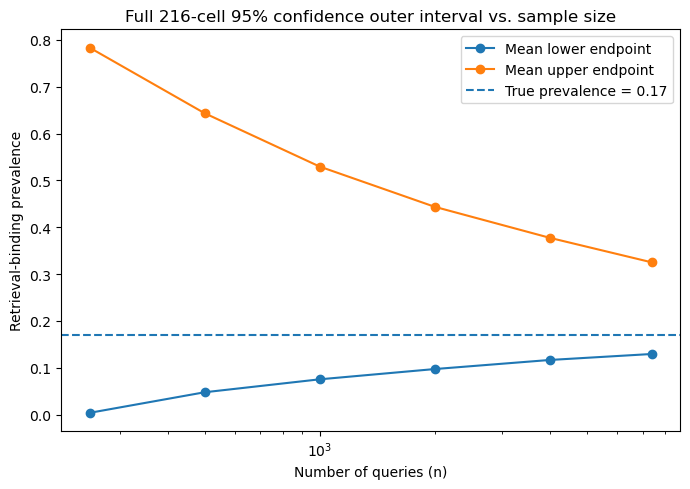

Saved: C:\Users\subir\Documents\RAG_Project\sample_size_design_K5.png


In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.plot(
    summary_n["n"],
    summary_n["mean_lower"],
    marker="o",
    label="Mean lower endpoint"
)

plt.plot(
    summary_n["n"],
    summary_n["mean_upper"],
    marker="o",
    label="Mean upper endpoint"
)

plt.axhline(
    true_binding,
    linestyle="--",
    label="True prevalence = 0.17"
)

plt.xscale("log")

plt.xlabel("Number of queries (n)")
plt.ylabel("Retrieval-binding prevalence")
plt.title("Full 216-cell 95% confidence outer interval vs. sample size")

plt.legend()
plt.tight_layout()

figure_path = os.path.join(
    project_folder,
    "sample_size_design_K5.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

In [25]:
# ============================================================
# REFINED SAMPLE-SIZE THRESHOLD STUDY
# When does the 95% lower bound become positive?
# ============================================================

n_fine = [250, 300, 350, 400, 450, 500]
R_fine = 40

rng_fine = np.random.default_rng(20261109)

fine_results = []

for n_test in n_fine:

    print("\n==============================")
    print("n =", n_test)
    print("==============================")

    for r in range(R_fine):

        # Draw observed 216-cell counts
        counts_r = rng_fine.multinomial(
            n_test,
            pi_pop
        )

        pi_r = counts_r / n_test

        # Bonferroni-Clopper-Pearson simultaneous box
        lo_r = np.zeros(M_cells)
        up_r = np.ones(M_cells)

        alpha_cell_r = alpha / M_cells

        for i, x in enumerate(counts_r):

            if x == 0:
                lo_r[i] = 0.0
            else:
                lo_r[i] = beta.ppf(
                    alpha_cell_r / 2,
                    x,
                    n_test - x + 1
                )

            if x == n_test:
                up_r[i] = 1.0
            else:
                up_r[i] = beta.ppf(
                    1 - alpha_cell_r / 2,
                    x + 1,
                    n_test - x
                )

        # Full 216-coordinate certificate
        result_r = full_coordinate_certificate(
            pi_r,
            cell_box=(lo_r, up_r)
        )

        fine_results.append({
            "n": n_test,
            "rep": r + 1,
            "lower": result_r["lower"],
            "upper": result_r["upper"],
            "width": result_r["upper"] - result_r["lower"],
            "positive_lower": result_r["lower"] > 0,
            "covered": (
                result_r["lower"]
                <= true_binding
                <= result_r["upper"]
            )
        })

    print("Finished n =", n_test)


# ------------------------------------------------------------
# Summarize
# ------------------------------------------------------------

fine_df = pd.DataFrame(fine_results)

fine_summary = (
    fine_df
    .groupby("n")
    .agg(
        positive_lower=("positive_lower", "mean"),
        coverage=("covered", "mean"),
        mean_lower=("lower", "mean"),
        mean_upper=("upper", "mean"),
        mean_width=("width", "mean"),
        median_width=("width", "median")
    )
    .reset_index()
)

display(fine_summary)


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

fine_path = os.path.join(
    project_folder,
    "mc_positive_lower_threshold.csv"
)

fine_summary_path = os.path.join(
    project_folder,
    "mc_positive_lower_threshold_summary.csv"
)

fine_df.to_csv(
    fine_path,
    index=False
)

fine_summary.to_csv(
    fine_summary_path,
    index=False
)

print("\nSaved:")
print(fine_path)
print(fine_summary_path)


n = 250
Finished n = 250

n = 300


RuntimeError: (HiGHS Status 0: Not Set)

In [26]:
# ============================================================
# ROBUST HiGHS WRAPPER
# Automatically retries if one solver configuration fails
# ============================================================

from scipy.optimize import linprog as _scipy_linprog

def linprog(*args, **kwargs):

    kwargs = dict(kwargs)

    # full_coordinate_certificate currently supplies method="highs".
    # Remove it so this wrapper can choose robust alternatives.
    kwargs.pop("method", None)

    original_options = dict(
        kwargs.pop("options", {}) or {}
    )

    attempts = [
        ("highs-ds", False),   # dual simplex, no presolve
        ("highs-ipm", False),  # interior point, no presolve
        ("highs", False),
        ("highs-ds", True),
        ("highs-ipm", True),
    ]

    last_result = None

    for method, presolve in attempts:

        options = dict(original_options)
        options["presolve"] = presolve

        result = _scipy_linprog(
            *args,
            method=method,
            options=options,
            **kwargs
        )

        if result.success:
            return result

        last_result = result

    # If every method failed, return the final result so
    # full_coordinate_certificate produces the usual error.
    return last_result


print("Robust HiGHS retry wrapper installed.")

Robust HiGHS retry wrapper installed.


In [27]:
check_result = full_coordinate_certificate(pi_pop)

print(check_result)
print(
    "Truth contained:",
    check_result["lower"] <= true_binding <= check_result["upper"]
)

{'lower': 0.1687464363081932, 'upper': 0.17400843304320562, 'coherent': True, 'lower_safety': np.float64(4.377966766474917e-09), 'upper_safety': np.float64(1.0585456951288325e-09)}
Truth contained: True


In [28]:
n_fine = [250, 300, 350, 400, 450, 500]
R_fine = 40

In [29]:
fine_results = []

In [30]:
rng_fine = np.random.default_rng(20261109)

fine_results = []

for n_test in n_fine:

    print("\n==============================")
    print("n =", n_test)
    print("==============================")

    for r in range(R_fine):

        counts_r = rng_fine.multinomial(
            n_test,
            pi_pop
        )

        pi_r = counts_r / n_test

        lo_r = np.zeros(M_cells)
        up_r = np.ones(M_cells)

        alpha_cell_r = alpha / M_cells

        for i, x in enumerate(counts_r):

            if x == 0:
                lo_r[i] = 0.0
            else:
                lo_r[i] = beta.ppf(
                    alpha_cell_r / 2,
                    x,
                    n_test - x + 1
                )

            if x == n_test:
                up_r[i] = 1.0
            else:
                up_r[i] = beta.ppf(
                    1 - alpha_cell_r / 2,
                    x + 1,
                    n_test - x
                )

        result_r = full_coordinate_certificate(
            pi_r,
            cell_box=(lo_r, up_r)
        )

        fine_results.append({
            "n": n_test,
            "rep": r + 1,
            "lower": result_r["lower"],
            "upper": result_r["upper"],
            "width": result_r["upper"] - result_r["lower"],
            "positive_lower": result_r["lower"] > 0,
            "covered": (
                result_r["lower"]
                <= true_binding
                <= result_r["upper"]
            )
        })

    print("Finished n =", n_test)


fine_df = pd.DataFrame(fine_results)

fine_summary = (
    fine_df
    .groupby("n")
    .agg(
        positive_lower=("positive_lower", "mean"),
        coverage=("covered", "mean"),
        mean_lower=("lower", "mean"),
        mean_upper=("upper", "mean"),
        mean_width=("width", "mean"),
        median_width=("width", "median")
    )
    .reset_index()
)

display(fine_summary)

fine_df.to_csv(
    os.path.join(
        project_folder,
        "mc_positive_lower_threshold.csv"
    ),
    index=False
)

fine_summary.to_csv(
    os.path.join(
        project_folder,
        "mc_positive_lower_threshold_summary.csv"
    ),
    index=False
)

print("Saved refined threshold results.")


n = 250
Finished n = 250

n = 300
Finished n = 300

n = 350
Finished n = 350

n = 400
Finished n = 400

n = 450
Finished n = 450

n = 500
Finished n = 500


,n,positive_lower,coverage,mean_lower,mean_upper,mean_width,median_width
0,250,0.150,1.0,0.001787,0.786804,0.785017,0.798208
1,300,0.600,1.0,0.011161,0.731345,0.720184,0.718207
2,350,0.675,1.0,0.016445,0.706003,0.689558,0.686028
3,400,0.800,1.0,0.019732,0.664025,0.644292,0.645120
4,450,0.950,1.0,0.035041,0.650539,0.615498,0.616289
5,500,0.975,1.0,0.050309,0.632867,0.582558,0.583314


Saved refined threshold results.


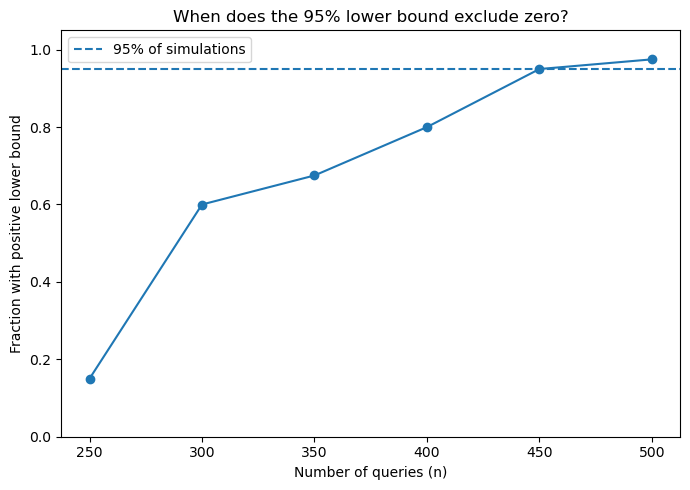

Saved: C:\Users\subir\Documents\RAG_Project\positive_lower_probability_K5.png


In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.plot(
    fine_summary["n"],
    fine_summary["positive_lower"],
    marker="o"
)

plt.axhline(
    0.95,
    linestyle="--",
    label="95% of simulations"
)

plt.xlabel("Number of queries (n)")
plt.ylabel("Fraction with positive lower bound")
plt.title("When does the 95% lower bound exclude zero?")

plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

threshold_fig = os.path.join(
    project_folder,
    "positive_lower_probability_K5.png"
)

plt.savefig(
    threshold_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", threshold_fig)

In [32]:
# ============================================================
# GENERALIZED FULL-COORDINATE SYSTEM FOR ARBITRARY K
# ============================================================

import itertools
import math
from collections import defaultdict

import numpy as np
import pandas as pd

from scipy.sparse import csc_matrix, eye, hstack, vstack


def build_certificate_system(K_local, delta_local):

    # --------------------------------------------------------
    # Local count cells and polynomial basis
    # --------------------------------------------------------

    cells = list(
        itertools.product(
            range(K_local + 1),
            repeat=3
        )
    )

    basis_local = list(
        itertools.product(
            range(K_local + 1),
            repeat=3
        )
    )

    basis_index_local = {
        e: i for i, e in enumerate(basis_local)
    }

    N = len(cells)

    # --------------------------------------------------------
    # Local polynomial utilities
    # --------------------------------------------------------

    def poly_mul_local(p, q):

        out = defaultdict(float)

        for e1, c1 in p.items():
            for e2, c2 in q.items():

                e = tuple(
                    e1[j] + e2[j]
                    for j in range(3)
                )

                if all(
                    v <= K_local
                    for v in e
                ):
                    out[e] += c1 * c2

        return {
            e: c
            for e, c in out.items()
            if abs(c) > 1e-14
        }


    def poly_pow_local(p, power):

        out = {
            (0, 0, 0): 1.0
        }

        for _ in range(power):
            out = poly_mul_local(
                out,
                p
            )

        return out


    def affine_local(constant, coeffs):

        out = {}

        if constant != 0:
            out[(0, 0, 0)] = float(constant)

        for j, a in enumerate(coeffs):

            if a != 0:

                e = [0, 0, 0]
                e[j] = 1

                out[tuple(e)] = float(a)

        return out


    def support_mask_local(poly):

        mask = set()

        for e in poly:

            for j, power in enumerate(e):

                if power:
                    mask.add(j)

        return tuple(sorted(mask))


    # --------------------------------------------------------
    # Bernstein polynomials
    # --------------------------------------------------------

    def bernstein_1d_poly_local(
        degree,
        index,
        variable
    ):

        out = {}

        for j in range(
            degree - index + 1
        ):

            e = [0, 0, 0]

            e[variable] = (
                index + j
            )

            out[tuple(e)] = (
                math.comb(
                    degree,
                    index
                )
                *
                math.comb(
                    degree - index,
                    j
                )
                *
                ((-1.0) ** j)
            )

        return out


    def tensor_bernstein_poly_local(
        degrees,
        indices
    ):

        out = {
            (0, 0, 0): 1.0
        }

        for variable, (
            degree,
            index
        ) in enumerate(
            zip(degrees, indices)
        ):

            out = poly_mul_local(
                out,
                bernstein_1d_poly_local(
                    degree,
                    index,
                    variable
                )
            )

        return out


    # --------------------------------------------------------
    # Monomial -> degree-K Bernstein transform
    # --------------------------------------------------------

    T_local = np.zeros(
        (N, len(basis_local))
    )

    for i, cell in enumerate(cells):

        for j, exponent in enumerate(
            basis_local
        ):

            if all(
                exponent[r] <= cell[r]
                for r in range(3)
            ):

                val = 1.0

                for r in range(3):

                    val *= (
                        math.comb(
                            cell[r],
                            exponent[r]
                        )
                        /
                        math.comb(
                            K_local,
                            exponent[r]
                        )
                    )

                T_local[i, j] = val


    # --------------------------------------------------------
    # Enumerate Handelman powers
    # --------------------------------------------------------

    def enumerate_constraint_powers_local(
        constraints
    ):

        masks = [
            support_mask_local(g)
            for g in constraints
        ]

        current = [
            0
        ] * len(constraints)

        def recurse(i, used):

            if i == len(constraints):

                yield tuple(current)
                return

            mask = masks[i]

            max_power = min(
                (
                    K_local - used[j]
                    for j in mask
                ),
                default=K_local
            )

            for a in range(
                max_power + 1
            ):

                current[i] = a

                new_used = (
                    used.copy()
                )

                for j in mask:
                    new_used[j] += a

                yield from recurse(
                    i + 1,
                    new_used
                )

        yield from recurse(
            0,
            [0, 0, 0]
        )


    # --------------------------------------------------------
    # Region cone
    # --------------------------------------------------------

    def region_cone_matrix_local(
        constraints
    ):

        masks = [
            support_mask_local(g)
            for g in constraints
        ]

        powers = [
            [
                poly_pow_local(
                    g,
                    r
                )
                for r in range(
                    K_local + 1
                )
            ]
            for g in constraints
        ]

        rows = []
        cols = []
        data = []

        column = 0

        for alpha_vec in (
            enumerate_constraint_powers_local(
                constraints
            )
        ):

            used = [0, 0, 0]

            product_poly = {
                (0, 0, 0): 1.0
            }

            for r, power in enumerate(
                alpha_vec
            ):

                if power:

                    product_poly = (
                        poly_mul_local(
                            product_poly,
                            powers[r][power]
                        )
                    )

                    for j in masks[r]:
                        used[j] += power

            residual_degree = tuple(
                K_local - used[j]
                for j in range(3)
            )

            ranges = [
                range(d + 1)
                for d in residual_degree
            ]

            for bern_index in (
                itertools.product(
                    *ranges
                )
            ):

                bpoly = (
                    tensor_bernstein_poly_local(
                        residual_degree,
                        bern_index
                    )
                )

                p = poly_mul_local(
                    bpoly,
                    product_poly
                )

                for exponent, value in (
                    p.items()
                ):

                    rows.append(
                        basis_index_local[
                            exponent
                        ]
                    )

                    cols.append(column)
                    data.append(value)

                column += 1

        return csc_matrix(
            (
                data,
                (rows, cols)
            ),
            shape=(
                len(basis_local),
                column
            )
        )


    # --------------------------------------------------------
    # Target region and complement pieces
    # --------------------------------------------------------

    target_constraints_local = [

        # y - x - delta >= 0
        affine_local(
            -delta_local,
            [-1, 1, 0]
        ),

        # x - z + delta >= 0
        affine_local(
            delta_local,
            [1, 0, -1]
        )
    ]

    complement_1_local = [

        # y - x <= delta
        affine_local(
            delta_local,
            [1, -1, 0]
        )
    ]

    complement_2_local = [

        # z - x >= delta
        affine_local(
            -delta_local,
            [-1, 0, 1]
        )
    ]


    HA_local = region_cone_matrix_local(
        target_constraints_local
    )

    H1_local = region_cone_matrix_local(
        complement_1_local
    )

    H2_local = region_cone_matrix_local(
        complement_2_local
    )

    BA_local = csc_matrix(
        T_local @ HA_local
    )

    B1_local = csc_matrix(
        T_local @ H1_local
    )

    B2_local = csc_matrix(
        T_local @ H2_local
    )


    # --------------------------------------------------------
    # Support function for box intersect simplex
    # --------------------------------------------------------

    def support_box_simplex_local(
        beta_coeff,
        lo,
        up
    ):

        beta_coeff = np.asarray(
            beta_coeff,
            dtype=float
        )

        lo = np.asarray(lo)
        up = np.asarray(up)

        capacity = up - lo

        remaining = (
            1.0 - lo.sum()
        )

        remaining = min(
            max(
                remaining,
                0.0
            ),
            capacity.sum()
        )

        value = float(
            beta_coeff @ lo
        )

        order = np.argsort(
            -beta_coeff
        )

        for i in order:

            if remaining <= 1e-15:
                break

            add = min(
                capacity[i],
                remaining
            )

            value += (
                beta_coeff[i]
                * add
            )

            remaining -= add

        return value


    # --------------------------------------------------------
    # Certificate function
    # --------------------------------------------------------

    def certificate(
        pi,
        cell_box=None
    ):

        pi = np.asarray(
            pi,
            dtype=float
        )

        ones = np.ones(N)

        # ====================================================
        # UPPER
        # ====================================================

        if cell_box is None:

            objective = np.asarray(
                BA_local.T @ pi
            ).ravel()

            upper_lp = linprog(
                objective,
                A_ub=-BA_local,
                b_ub=ones,
                bounds=[
                    (0, None)
                ] * HA_local.shape[1],
                method="highs"
            )

        else:

            lo, up = cell_box

            capacity = up - lo

            remaining = (
                1.0 - lo.sum()
            )

            objective = np.r_[

                np.asarray(
                    BA_local.T @ lo
                ).ravel(),

                remaining,

                capacity
            ]

            row1 = hstack(
                [
                    -BA_local,
                    csc_matrix(
                        (N, 1 + N)
                    )
                ],
                format="csc"
            )

            row2 = hstack(
                [
                    BA_local,
                    -np.ones((N, 1)),
                    -eye(
                        N,
                        format="csc"
                    )
                ],
                format="csc"
            )

            upper_lp = linprog(
                objective,
                A_ub=vstack(
                    [row1, row2],
                    format="csc"
                ),
                b_ub=np.r_[
                    ones,
                    np.zeros(N)
                ],
                bounds=(
                    [(0, None)]
                    * HA_local.shape[1]
                    +
                    [(None, None)]
                    +
                    [(0, None)] * N
                ),
                method="highs"
            )

        if not upper_lp.success:

            raise RuntimeError(
                "Upper LP failed: "
                + upper_lp.message
            )

        lam_upper = np.maximum(
            upper_lp.x[
                :HA_local.shape[1]
            ],
            0
        )

        theta_upper = np.zeros(
            len(basis_local)
        )

        theta_upper[0] = 1.0

        theta_upper += (
            HA_local @ lam_upper
        )

        beta_upper = (
            T_local @ theta_upper
        )

        safety_upper = (
            max(
                0,
                -beta_upper.min()
            )
            + 5e-12
        )

        beta_upper += safety_upper

        if cell_box is None:

            upper_value = float(
                beta_upper @ pi
            )

        else:

            upper_value = (
                support_box_simplex_local(
                    beta_upper,
                    *cell_box
                )
            )


        # ====================================================
        # LOWER via complement majorant
        # ====================================================

        n1 = H1_local.shape[1]
        n2 = H2_local.shape[1]

        A_eq = hstack(
            [
                H1_local,
                -H2_local
            ],
            format="csc"
        )

        if cell_box is not None:

            A_eq = hstack(
                [
                    A_eq,
                    csc_matrix(
                        (
                            len(basis_local),
                            1 + N
                        )
                    )
                ],
                format="csc"
            )

        b_eq = np.zeros(
            len(basis_local)
        )


        if cell_box is None:

            objective = np.r_[

                np.asarray(
                    B1_local.T @ pi
                ).ravel(),

                np.zeros(n2)
            ]

            A_ub = hstack(
                [
                    -B1_local,
                    csc_matrix(
                        (N, n2)
                    )
                ],
                format="csc"
            )

            lower_lp = linprog(
                objective,
                A_ub=A_ub,
                b_ub=ones,
                A_eq=A_eq,
                b_eq=b_eq,
                bounds=(
                    [(0, None)] * n1
                    +
                    [(0, None)] * n2
                ),
                method="highs"
            )

        else:

            lo, up = cell_box

            capacity = up - lo

            remaining = (
                1.0 - lo.sum()
            )

            objective = np.r_[

                np.asarray(
                    B1_local.T @ lo
                ).ravel(),

                np.zeros(n2),

                remaining,

                capacity
            ]

            row1 = hstack(
                [
                    -B1_local,
                    csc_matrix(
                        (N, n2)
                    ),
                    csc_matrix(
                        (N, 1 + N)
                    )
                ],
                format="csc"
            )

            row2 = hstack(
                [
                    B1_local,
                    csc_matrix(
                        (N, n2)
                    ),
                    -np.ones((N, 1)),
                    -eye(
                        N,
                        format="csc"
                    )
                ],
                format="csc"
            )

            lower_lp = linprog(
                objective,
                A_ub=vstack(
                    [row1, row2],
                    format="csc"
                ),
                b_ub=np.r_[
                    ones,
                    np.zeros(N)
                ],
                A_eq=A_eq,
                b_eq=b_eq,
                bounds=(
                    [(0, None)] * n1
                    +
                    [(0, None)] * n2
                    +
                    [(None, None)]
                    +
                    [(0, None)] * N
                ),
                method="highs"
            )


        if not lower_lp.success:

            raise RuntimeError(
                "Lower LP failed: "
                + lower_lp.message
            )

        lam1 = np.maximum(
            lower_lp.x[:n1],
            0
        )

        lam2 = np.maximum(
            lower_lp.x[
                n1:n1+n2
            ],
            0
        )

        theta_lower = np.zeros(
            len(basis_local)
        )

        theta_lower[0] = 1.0

        base = (
            H1_local @ lam1
        )

        theta_lower += base

        beta_lower = (
            T_local @ theta_lower
        )

        residual = (
            base
            -
            H2_local @ lam2
        )

        safety_lower = (
            max(
                0,
                -beta_lower.min(),
                np.abs(
                    residual
                ).sum()
            )
            + 5e-12
        )

        beta_lower += safety_lower


        if cell_box is None:

            complement_upper = float(
                beta_lower @ pi
            )

        else:

            complement_upper = (
                support_box_simplex_local(
                    beta_lower,
                    *cell_box
                )
            )

        lower_value = (
            1.0
            -
            complement_upper
        )

        lower_value = max(
            0.0,
            min(
                1.0,
                lower_value
            )
        )

        upper_value = max(
            0.0,
            min(
                1.0,
                upper_value
            )
        )

        return {
            "lower": lower_value,
            "upper": upper_value,
            "coherent":
                lower_value
                <= upper_value
                + 1e-7,
            "lower_safety":
                safety_lower,
            "upper_safety":
                safety_upper
        }


    return {
        "K": K_local,
        "cells": cells,
        "N": N,
        "certificate": certificate,
        "T": T_local,
        "HA": HA_local,
        "H1": H1_local,
        "H2": H2_local
    }


print("General K certificate builder ready.")

General K certificate builder ready.


In [33]:
systems = {}

for K_test in [2, 3, 4, 5]:

    print("Building K =", K_test)

    systems[K_test] = (
        build_certificate_system(
            K_test,
            delta
        )
    )

    print(
        "  cells:",
        systems[K_test]["N"]
    )

print("All systems built.")

Building K = 2
  cells: 27
Building K = 3
  cells: 64
Building K = 4
  cells: 125
Building K = 5
  cells: 216
All systems built.


In [34]:
# ============================================================
# POPULATION CHECK ACROSS K
# ============================================================

def population_count_distribution(K_test):

    cells = systems[K_test]["cells"]

    pi = np.zeros(len(cells))

    for _, row in latent_types.iterrows():

        probs = np.array([
            bernstein_cell(
                cell,
                row["p_FF"],
                row["p_IF"],
                row["p_FI"],
                K=K_test
            )
            for cell in cells
        ])

        pi += row["weight"] * probs

    return pi


population_by_K = {}
population_checks = []

for K_test in [2, 3, 4, 5]:

    pi_K = population_count_distribution(K_test)

    population_by_K[K_test] = pi_K

    cert_K = systems[K_test]["certificate"](
        pi_K
    )

    population_checks.append({
        "K": K_test,
        "lower": cert_K["lower"],
        "upper": cert_K["upper"],
        "width": cert_K["upper"] - cert_K["lower"],
        "contains_truth": (
            cert_K["lower"]
            <= true_binding
            <= cert_K["upper"]
        )
    })


population_check_df = pd.DataFrame(
    population_checks
)

display(population_check_df)

,K,lower,upper,width,contains_truth
0,2,0.145696,0.238105,0.092409,True
1,3,0.154300,0.219187,0.064886,True
2,4,0.168053,0.175560,0.007507,True
3,5,0.168746,0.174008,0.005262,True


In [35]:
population_check_df.to_csv(
    os.path.join(
        project_folder,
        "population_identification_by_K.csv"
    ),
    index=False
)

print("Population K table saved.")

Population K table saved.


In [36]:
# ============================================================
# n x K MONTE CARLO STUDY
# ============================================================

K_grid = [2, 3, 4, 5]
n_grid_K = [500, 1000, 2000]

# Preliminary simulation size.
# We can increase this later for the final paper.
R_K = 20

rng_K = np.random.default_rng(20261110)

nk_results = []


for K_test in K_grid:

    system = systems[K_test]

    cells_K = system["cells"]
    cert_fun = system["certificate"]

    pi_population = population_by_K[K_test]

    M_K = len(cells_K)

    print("\n################################")
    print("K =", K_test)
    print("Number of cells =", M_K)
    print("################################")

    for n_test in n_grid_K:

        print("\n------------------------------")
        print("n =", n_test)
        print("------------------------------")

        for r in range(R_K):

            # ---------------------------------------------
            # Draw observed count-cell frequencies
            # ---------------------------------------------

            counts_r = rng_K.multinomial(
                n_test,
                pi_population
            )

            pi_r = counts_r / n_test


            # ---------------------------------------------
            # Exact simultaneous Bonferroni-CP region
            # ---------------------------------------------

            lo_r = np.zeros(M_K)
            up_r = np.ones(M_K)

            alpha_cell_r = alpha / M_K


            for i, x in enumerate(counts_r):

                if x == 0:

                    lo_r[i] = 0.0

                else:

                    lo_r[i] = beta.ppf(
                        alpha_cell_r / 2,
                        x,
                        n_test - x + 1
                    )


                if x == n_test:

                    up_r[i] = 1.0

                else:

                    up_r[i] = beta.ppf(
                        1 - alpha_cell_r / 2,
                        x + 1,
                        n_test - x
                    )


            # ---------------------------------------------
            # Full-coordinate confidence outer interval
            # ---------------------------------------------

            result_r = cert_fun(
                pi_r,
                cell_box=(lo_r, up_r)
            )


            nk_results.append({

                "K": K_test,
                "n": n_test,
                "rep": r + 1,

                "lower":
                    result_r["lower"],

                "upper":
                    result_r["upper"],

                "width":
                    result_r["upper"]
                    - result_r["lower"],

                "covered":
                    result_r["lower"]
                    <= true_binding
                    <= result_r["upper"],

                "positive_lower":
                    result_r["lower"] > 0
            })


        print(
            "Finished K =",
            K_test,
            "n =",
            n_test
        )


# ============================================================
# SUMMARIZE
# ============================================================

nk_df = pd.DataFrame(
    nk_results
)


nk_summary = (
    nk_df
    .groupby(["K", "n"])
    .agg(

        coverage=(
            "covered",
            "mean"
        ),

        positive_lower=(
            "positive_lower",
            "mean"
        ),

        mean_lower=(
            "lower",
            "mean"
        ),

        mean_upper=(
            "upper",
            "mean"
        ),

        mean_width=(
            "width",
            "mean"
        ),

        median_width=(
            "width",
            "median"
        )
    )
    .reset_index()
)


display(nk_summary)


# ============================================================
# SAVE
# ============================================================

nk_path = os.path.join(
    project_folder,
    "mc_n_by_K.csv"
)

nk_summary_path = os.path.join(
    project_folder,
    "mc_n_by_K_summary.csv"
)


nk_df.to_csv(
    nk_path,
    index=False
)

nk_summary.to_csv(
    nk_summary_path,
    index=False
)


print("\nSaved:")
print(nk_path)
print(nk_summary_path)


################################
K = 2
Number of cells = 27
################################

------------------------------
n = 500
------------------------------
Finished K = 2 n = 500

------------------------------
n = 1000
------------------------------
Finished K = 2 n = 1000

------------------------------
n = 2000
------------------------------
Finished K = 2 n = 2000

################################
K = 3
Number of cells = 64
################################

------------------------------
n = 500
------------------------------
Finished K = 3 n = 500

------------------------------
n = 1000
------------------------------
Finished K = 3 n = 1000

------------------------------
n = 2000
------------------------------
Finished K = 3 n = 2000

################################
K = 4
Number of cells = 125
################################

------------------------------
n = 500
------------------------------
Finished K = 4 n = 500

------------------------------
n = 1000
----------

,K,n,coverage,positive_lower,mean_lower,mean_upper,mean_width,median_width
0,2,500,1.0,0.7,0.017506,0.644829,0.627323,0.633441
1,2,1000,1.0,1.0,0.060921,0.528281,0.467360,0.466301
2,2,2000,1.0,1.0,0.089035,0.402824,0.313790,0.309283
3,3,500,1.0,1.0,0.040939,0.610340,0.569401,0.553164
4,3,1000,1.0,1.0,0.081015,0.504482,0.423467,0.428557
5,3,2000,1.0,1.0,0.101124,0.426990,0.325866,0.322433
6,4,500,1.0,1.0,0.038693,0.629998,0.591305,0.600910
7,4,1000,1.0,1.0,0.078320,0.512204,0.433884,0.433560
8,4,2000,1.0,1.0,0.099021,0.434289,0.335269,0.333897
9,5,500,1.0,1.0,0.040698,0.627070,0.586372,0.584451



Saved:
C:\Users\subir\Documents\RAG_Project\mc_n_by_K.csv
C:\Users\subir\Documents\RAG_Project\mc_n_by_K_summary.csv


In [37]:
# ============================================================
# COVARIANCE-AWARE MULTINOMIAL MAX-t REGION
# ============================================================

def multinomial_maxt_box(
    cell_counts,
    alpha=0.05,
    B=20000,
    seed=20261111,
    smooth=0.5,
    batch_size=2000
):
    """
    Gaussian max-t approximation for multinomial cell probabilities.

    Jeffreys smoothing is used only to estimate variances/covariances,
    so empty empirical cells do not receive zero standard error.

    The confidence box itself remains centered at the observed
    empirical cell probabilities.
    """

    cell_counts = np.asarray(
        cell_counts,
        dtype=float
    )

    n_local = cell_counts.sum()
    M_local = len(cell_counts)

    pi_emp = cell_counts / n_local

    # Jeffreys-smoothed probability vector for estimating
    # the multinomial covariance structure.
    pi_var = (
        cell_counts + smooth
    ) / (
        n_local + smooth * M_local
    )

    # SD of sqrt(n) * (pi_hat - pi)
    sd_rootn = np.sqrt(
        pi_var * (1.0 - pi_var)
    )

    # Standard error of pi_hat
    se = sd_rootn / np.sqrt(n_local)

    rng = np.random.default_rng(seed)

    max_stats = []

    sqrt_pi = np.sqrt(pi_var)

    for start in range(
        0,
        B,
        batch_size
    ):

        b = min(
            batch_size,
            B - start
        )

        # Independent Gaussian variables
        G = rng.standard_normal(
            (b, M_local)
        )

        # Multinomial Gaussian process:
        #
        # Cov(Y) = diag(pi) - pi*pi'
        #
        shared = G @ sqrt_pi

        Y = (
            G * sqrt_pi
            -
            shared[:, None] * pi_var[None, :]
        )

        # Studentize coordinatewise
        T = np.max(
            np.abs(Y)
            / sd_rootn[None, :],
            axis=1
        )

        max_stats.append(T)

    max_stats = np.concatenate(
        max_stats
    )

    critical_value = np.quantile(
        max_stats,
        1.0 - alpha
    )

    halfwidth = (
        critical_value * se
    )

    lo = np.maximum(
        0.0,
        pi_emp - halfwidth
    )

    up = np.minimum(
        1.0,
        pi_emp + halfwidth
    )

    return {
        "critical_value": critical_value,
        "lower": lo,
        "upper": up,
        "halfwidth": halfwidth,
        "pi_emp": pi_emp,
        "pi_var": pi_var
    }


print("Multinomial max-t function ready.")

Multinomial max-t function ready.


In [38]:
# ============================================================
# APPLY MAX-t TO THE EXISTING n=1000, K=5 SAMPLE
# ============================================================

maxt_result = multinomial_maxt_box(
    observed_cell_counts,
    alpha=alpha,
    B=20000,
    seed=20261111
)

maxt_lower = maxt_result["lower"]
maxt_upper = maxt_result["upper"]

print(
    "Max-t critical value:",
    maxt_result["critical_value"]
)

print(
    "Median max-t half-width:",
    np.median(
        maxt_result["halfwidth"]
    )
)

print(
    "Max-t upper bound for an empty cell:",
    maxt_upper[
        observed_cell_counts == 0
    ][0]
)


# Propagate through full 216-coordinate certificate
full_outer_maxt = full_coordinate_certificate(
    pi_hat,
    cell_box=(
        maxt_lower,
        maxt_upper
    )
)

print("\nCovariance-aware count-cell max-t outer interval:")
print(full_outer_maxt)

print("\nExact CP/Bonferroni outer interval:")
print(full_outer)

print("\nTrue prevalence:")
print(true_binding)

Max-t critical value: 3.6633922769106917
Median max-t half-width: 0.0024603706335246415
Max-t upper bound for an empty cell: 0.0024603706335246415

Covariance-aware count-cell max-t outer interval:
{'lower': np.float64(0.0938804102457278), 'upper': np.float64(0.49086560921446987), 'coherent': np.True_, 'lower_safety': np.float64(1.674101744647049e-11), 'upper_safety': np.float64(7.70716782324598e-12)}

Exact CP/Bonferroni outer interval:
{'lower': np.float64(0.07725861502101483), 'upper': np.float64(0.5458256142044973), 'coherent': np.True_, 'lower_safety': np.float64(1.6417995240434975e-09), 'upper_safety': np.float64(5.341060513164848e-12)}

True prevalence:
0.17


In [39]:
comparison_df = pd.DataFrame([
    {
        "method": "Exact Bonferroni-CP",
        "lower": full_outer["lower"],
        "upper": full_outer["upper"],
        "width": (
            full_outer["upper"]
            - full_outer["lower"]
        )
    },
    {
        "method": "Covariance-aware max-t",
        "lower": full_outer_maxt["lower"],
        "upper": full_outer_maxt["upper"],
        "width": (
            full_outer_maxt["upper"]
            - full_outer_maxt["lower"]
        )
    }
])

display(comparison_df)

comparison_df.to_csv(
    os.path.join(
        project_folder,
        "count_cell_inference_comparison.csv"
    ),
    index=False
)

print("Saved inference comparison.")

,method,lower,upper,width
0,Exact Bonferroni-CP,0.077259,0.545826,0.468567
1,Covariance-aware max-t,0.093880,0.490866,0.396985


Saved inference comparison.


In [40]:
# ============================================================
# COVERAGE CHECK:
# COUNT-CELL MAX-t vs EXACT CP
# K = 5, n = 1000
# ============================================================

R_cov = 50
B_cov = 5000
n_cov = 1000

rng_cov = np.random.default_rng(20261112)

coverage_results = []

for r in range(R_cov):

    # --------------------------------------------------------
    # Draw sample
    # --------------------------------------------------------

    counts_r = rng_cov.multinomial(
        n_cov,
        pi_pop
    )

    pi_r = counts_r / n_cov


    # --------------------------------------------------------
    # EXACT Bonferroni-Clopper-Pearson region
    # --------------------------------------------------------

    lo_cp = np.zeros(M_cells)
    up_cp = np.ones(M_cells)

    alpha_cell_r = alpha / M_cells

    for i, x in enumerate(counts_r):

        if x == 0:
            lo_cp[i] = 0.0
        else:
            lo_cp[i] = beta.ppf(
                alpha_cell_r / 2,
                x,
                n_cov - x + 1
            )

        if x == n_cov:
            up_cp[i] = 1.0
        else:
            up_cp[i] = beta.ppf(
                1 - alpha_cell_r / 2,
                x + 1,
                n_cov - x
            )


    cp_result = full_coordinate_certificate(
        pi_r,
        cell_box=(lo_cp, up_cp)
    )


    # --------------------------------------------------------
    # Covariance-aware count-cell max-t region
    # --------------------------------------------------------

    maxt_r = multinomial_maxt_box(
        counts_r,
        alpha=alpha,
        B=B_cov,
        seed=20261112 + r
    )

    maxt_result_r = full_coordinate_certificate(
        pi_r,
        cell_box=(
            maxt_r["lower"],
            maxt_r["upper"]
        )
    )


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    coverage_results.append({

        "rep": r + 1,

        "cp_lower":
            cp_result["lower"],

        "cp_upper":
            cp_result["upper"],

        "cp_width":
            cp_result["upper"]
            - cp_result["lower"],

        "cp_covered":
            cp_result["lower"]
            <= true_binding
            <= cp_result["upper"],


        "maxt_lower":
            maxt_result_r["lower"],

        "maxt_upper":
            maxt_result_r["upper"],

        "maxt_width":
            maxt_result_r["upper"]
            - maxt_result_r["lower"],

        "maxt_covered":
            maxt_result_r["lower"]
            <= true_binding
            <= maxt_result_r["upper"],

        "critical_value":
            maxt_r["critical_value"]
    })

    print(
        f"{r+1:2d}/{R_cov} "
        f"CP=[{cp_result['lower']:.3f}, "
        f"{cp_result['upper']:.3f}] "
        f"MAXT=[{maxt_result_r['lower']:.3f}, "
        f"{maxt_result_r['upper']:.3f}]"
    )


coverage_df = pd.DataFrame(
    coverage_results
)


coverage_summary = pd.DataFrame({

    "method": [
        "Exact Bonferroni-CP",
        "Count-cell max-t"
    ],

    "coverage": [
        coverage_df["cp_covered"].mean(),
        coverage_df["maxt_covered"].mean()
    ],

    "mean_lower": [
        coverage_df["cp_lower"].mean(),
        coverage_df["maxt_lower"].mean()
    ],

    "mean_upper": [
        coverage_df["cp_upper"].mean(),
        coverage_df["maxt_upper"].mean()
    ],

    "mean_width": [
        coverage_df["cp_width"].mean(),
        coverage_df["maxt_width"].mean()
    ],

    "median_width": [
        coverage_df["cp_width"].median(),
        coverage_df["maxt_width"].median()
    ]
})

display(coverage_summary)

print(
    "\nMean max-t critical value:",
    coverage_df["critical_value"].mean()
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

coverage_df.to_csv(
    os.path.join(
        project_folder,
        "mc_countcell_maxt_coverage.csv"
    ),
    index=False
)

coverage_summary.to_csv(
    os.path.join(
        project_folder,
        "mc_countcell_maxt_coverage_summary.csv"
    ),
    index=False
)

print("\nSaved max-t coverage study.")

 1/50 CP=[0.081, 0.499] MAXT=[0.091, 0.483]
 2/50 CP=[0.077, 0.494] MAXT=[0.086, 0.462]
 3/50 CP=[0.076, 0.524] MAXT=[0.086, 0.504]
 4/50 CP=[0.066, 0.521] MAXT=[0.080, 0.479]
 5/50 CP=[0.084, 0.542] MAXT=[0.099, 0.494]
 6/50 CP=[0.066, 0.513] MAXT=[0.082, 0.485]
 7/50 CP=[0.080, 0.543] MAXT=[0.090, 0.489]
 8/50 CP=[0.064, 0.512] MAXT=[0.080, 0.477]
 9/50 CP=[0.078, 0.533] MAXT=[0.097, 0.494]
10/50 CP=[0.078, 0.554] MAXT=[0.097, 0.512]
11/50 CP=[0.092, 0.539] MAXT=[0.102, 0.508]
12/50 CP=[0.073, 0.522] MAXT=[0.090, 0.479]
13/50 CP=[0.085, 0.513] MAXT=[0.094, 0.486]
14/50 CP=[0.088, 0.518] MAXT=[0.098, 0.476]
15/50 CP=[0.074, 0.524] MAXT=[0.087, 0.484]
16/50 CP=[0.076, 0.528] MAXT=[0.095, 0.497]
17/50 CP=[0.078, 0.527] MAXT=[0.091, 0.483]
18/50 CP=[0.093, 0.532] MAXT=[0.103, 0.480]
19/50 CP=[0.070, 0.525] MAXT=[0.095, 0.502]
20/50 CP=[0.085, 0.528] MAXT=[0.105, 0.508]
21/50 CP=[0.065, 0.517] MAXT=[0.087, 0.476]
22/50 CP=[0.055, 0.560] MAXT=[0.085, 0.496]
23/50 CP=[0.064, 0.537] MAXT=[0.

,method,coverage,mean_lower,mean_upper,mean_width,median_width
0,Exact Bonferroni-CP,1.0,0.076834,0.527864,0.451031,0.451388
1,Count-cell max-t,1.0,0.092527,0.490202,0.397675,0.396888



Mean max-t critical value: 3.6779097042476177

Saved max-t coverage study.


In [41]:
# ============================================================
# CELL 1
# SETUP
# ============================================================

import os
import math
import itertools

from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import linprog as scipy_linprog
from scipy.stats import beta
from scipy.sparse import csc_matrix, eye, hstack, vstack


# ------------------------------------------------------------
# Project folder
# ------------------------------------------------------------

project_folder = r"C:\Users\subir\Documents\RAG_Project"

os.makedirs(
    project_folder,
    exist_ok=True
)

print("Project folder:")
print(project_folder)


# ------------------------------------------------------------
# Main settings
# ------------------------------------------------------------

delta = 0.10
alpha = 0.05

print("\ndelta =", delta)
print("alpha =", alpha)


# ------------------------------------------------------------
# Robust HiGHS solver
# ------------------------------------------------------------

def solve_lp(*args, **kwargs):

    kwargs = dict(kwargs)

    # Remove method if supplied elsewhere
    kwargs.pop("method", None)

    original_options = dict(
        kwargs.pop("options", {}) or {}
    )

    attempts = [
        ("highs-ds", False),
        ("highs-ipm", False),
        ("highs", False),
        ("highs-ds", True),
        ("highs-ipm", True),
    ]

    last_result = None

    for method, presolve in attempts:

        options = dict(original_options)
        options["presolve"] = presolve

        result = scipy_linprog(
            *args,
            method=method,
            options=options,
            **kwargs
        )

        if result.success:
            return result

        last_result = result

    return last_result


print("\nRobust LP solver ready.")

Project folder:
C:\Users\subir\Documents\RAG_Project

delta = 0.1
alpha = 0.05

Robust LP solver ready.


In [42]:
# ============================================================
# CELL 2
# BERNSTEIN COUNT PROBABILITIES + SYNTHETIC DGP
# ============================================================

def bernstein_1d_numeric(K, c, p):

    return (
        math.comb(K, c)
        * (p ** c)
        * ((1.0 - p) ** (K - c))
    )


def bernstein_cell_numeric(
    cell,
    p_ff,
    p_if,
    p_fi,
    K
):

    c_ff, c_if, c_fi = cell

    return (
        bernstein_1d_numeric(
            K,
            c_ff,
            p_ff
        )
        *
        bernstein_1d_numeric(
            K,
            c_if,
            p_if
        )
        *
        bernstein_1d_numeric(
            K,
            c_fi,
            p_fi
        )
    )


# ------------------------------------------------------------
# HotpotQA-like corner-concentrated DGP
# ------------------------------------------------------------

low = 0.0075
high = 0.9925

latent_types = pd.DataFrame(
    [
        [low,  low,  low,  0.30],
        [high, high, high, 0.25],

        # retrieval-binding
        [low,  high, low,  0.17],

        # retrieval-harmful
        [high, low,  high, 0.04],

        # generator-helpful
        [low,  low,  high, 0.12],

        # both improve
        [low,  high, high, 0.12],
    ],
    columns=[
        "p_FF",
        "p_IF",
        "p_FI",
        "weight"
    ]
)


DR = (
    latent_types["p_IF"]
    -
    latent_types["p_FF"]
)

DG = (
    latent_types["p_FI"]
    -
    latent_types["p_FF"]
)


is_binding = (
    (DR > delta)
    &
    (DG <= delta)
)

true_binding = latent_types.loc[
    is_binding,
    "weight"
].sum()


is_harm = (
    DR < -delta
)

true_harm = latent_types.loc[
    is_harm,
    "weight"
].sum()


display(latent_types)

print(
    "\nWeights sum:",
    latent_types["weight"].sum()
)

print(
    "True retrieval-binding prevalence:",
    true_binding
)

print(
    "True retrieval-harmful prevalence:",
    true_harm
)

,p_FF,p_IF,p_FI,weight
0,0.0075,0.0075,0.0075,0.30
1,0.9925,0.9925,0.9925,0.25
2,0.0075,0.9925,0.0075,0.17
3,0.9925,0.0075,0.9925,0.04
4,0.0075,0.0075,0.9925,0.12
5,0.0075,0.9925,0.9925,0.12



Weights sum: 1.0
True retrieval-binding prevalence: 0.17
True retrieval-harmful prevalence: 0.04


In [43]:
# ============================================================
# CELL 3
# GENERAL FULL-COORDINATE BERNSTEIN-HANDELMAN SYSTEM
# ============================================================

def build_certificate_system(
    K_local,
    delta_local
):

    # --------------------------------------------------------
    # Count cells and polynomial basis
    # --------------------------------------------------------

    cells = list(
        itertools.product(
            range(K_local + 1),
            repeat=3
        )
    )

    basis = list(
        itertools.product(
            range(K_local + 1),
            repeat=3
        )
    )

    basis_index = {
        exponent: i
        for i, exponent
        in enumerate(basis)
    }

    N = len(cells)


    # --------------------------------------------------------
    # Polynomial multiplication
    # --------------------------------------------------------

    def poly_mul(p, q):

        out = defaultdict(float)

        for e1, c1 in p.items():

            for e2, c2 in q.items():

                exponent = tuple(
                    e1[j] + e2[j]
                    for j in range(3)
                )

                if all(
                    degree <= K_local
                    for degree in exponent
                ):

                    out[exponent] += (
                        c1 * c2
                    )

        return {
            exponent: coefficient
            for exponent, coefficient
            in out.items()
            if abs(coefficient) > 1e-14
        }


    def poly_pow(p, power):

        out = {
            (0, 0, 0): 1.0
        }

        for _ in range(power):

            out = poly_mul(
                out,
                p
            )

        return out


    def affine(
        constant,
        coeffs
    ):

        out = {}

        if constant != 0:

            out[(0, 0, 0)] = float(
                constant
            )

        for j, coefficient in enumerate(
            coeffs
        ):

            if coefficient != 0:

                exponent = [0, 0, 0]

                exponent[j] = 1

                out[tuple(exponent)] = float(
                    coefficient
                )

        return out


    def support_mask(poly):

        mask = set()

        for exponent in poly:

            for j, power in enumerate(
                exponent
            ):

                if power:
                    mask.add(j)

        return tuple(
            sorted(mask)
        )


    # --------------------------------------------------------
    # Bernstein polynomial basis
    # --------------------------------------------------------

    def bernstein_1d_poly(
        degree,
        index,
        variable
    ):

        out = {}

        for j in range(
            degree - index + 1
        ):

            exponent = [0, 0, 0]

            exponent[variable] = (
                index + j
            )

            out[tuple(exponent)] = (
                math.comb(
                    degree,
                    index
                )
                *
                math.comb(
                    degree - index,
                    j
                )
                *
                ((-1.0) ** j)
            )

        return out


    def tensor_bernstein_poly(
        degrees,
        indices
    ):

        out = {
            (0, 0, 0): 1.0
        }

        for variable, (
            degree,
            index
        ) in enumerate(
            zip(degrees, indices)
        ):

            out = poly_mul(
                out,
                bernstein_1d_poly(
                    degree,
                    index,
                    variable
                )
            )

        return out


    # --------------------------------------------------------
    # Monomial -> tensor Bernstein transformation
    # --------------------------------------------------------

    T = np.zeros(
        (
            N,
            len(basis)
        )
    )

    for i, cell in enumerate(cells):

        for j, exponent in enumerate(
            basis
        ):

            if all(
                exponent[r] <= cell[r]
                for r in range(3)
            ):

                value = 1.0

                for r in range(3):

                    value *= (
                        math.comb(
                            cell[r],
                            exponent[r]
                        )
                        /
                        math.comb(
                            K_local,
                            exponent[r]
                        )
                    )

                T[i, j] = value


    # --------------------------------------------------------
    # Constraint-product enumeration
    # --------------------------------------------------------

    def enumerate_constraint_powers(
        constraints
    ):

        masks = [
            support_mask(g)
            for g in constraints
        ]

        current = [
            0
        ] * len(constraints)


        def recurse(i, used):

            if i == len(constraints):

                yield tuple(current)
                return

            mask = masks[i]

            max_power = min(
                (
                    K_local
                    -
                    used[j]
                    for j in mask
                ),
                default=K_local
            )

            for power in range(
                max_power + 1
            ):

                current[i] = power

                new_used = used.copy()

                for j in mask:

                    new_used[j] += power

                yield from recurse(
                    i + 1,
                    new_used
                )


        yield from recurse(
            0,
            [0, 0, 0]
        )


    # --------------------------------------------------------
    # Region cone
    # --------------------------------------------------------

    def region_cone_matrix(
        constraints
    ):

        masks = [
            support_mask(g)
            for g in constraints
        ]

        powers = [
            [
                poly_pow(
                    g,
                    r
                )
                for r in range(
                    K_local + 1
                )
            ]
            for g in constraints
        ]

        rows = []
        cols = []
        data = []

        column = 0


        for alpha_vec in (
            enumerate_constraint_powers(
                constraints
            )
        ):

            used = [
                0,
                0,
                0
            ]

            product_poly = {
                (0, 0, 0): 1.0
            }


            for r, power in enumerate(
                alpha_vec
            ):

                if power:

                    product_poly = poly_mul(
                        product_poly,
                        powers[r][power]
                    )

                    for j in masks[r]:

                        used[j] += power


            residual_degree = tuple(
                K_local - used[j]
                for j in range(3)
            )


            ranges = [
                range(d + 1)
                for d in residual_degree
            ]


            for bern_index in (
                itertools.product(
                    *ranges
                )
            ):

                bern_poly = (
                    tensor_bernstein_poly(
                        residual_degree,
                        bern_index
                    )
                )

                product = poly_mul(
                    bern_poly,
                    product_poly
                )


                for (
                    exponent,
                    coefficient
                ) in product.items():

                    rows.append(
                        basis_index[
                            exponent
                        ]
                    )

                    cols.append(column)

                    data.append(
                        coefficient
                    )


                column += 1


        return csc_matrix(
            (
                data,
                (rows, cols)
            ),
            shape=(
                len(basis),
                column
            )
        )


    # --------------------------------------------------------
    # Retrieval-binding target
    #
    # y - x > delta
    # z - x <= delta
    # --------------------------------------------------------

    target_constraints = [

        # y - x - delta >= 0
        affine(
            -delta_local,
            [-1, 1, 0]
        ),

        # x - z + delta >= 0
        affine(
            delta_local,
            [1, 0, -1]
        )
    ]


    # Complement:
    #
    # y - x <= delta
    complement_1 = [

        affine(
            delta_local,
            [1, -1, 0]
        )
    ]


    # z - x >= delta
    complement_2 = [

        affine(
            -delta_local,
            [-1, 0, 1]
        )
    ]


    HA = region_cone_matrix(
        target_constraints
    )

    H1 = region_cone_matrix(
        complement_1
    )

    H2 = region_cone_matrix(
        complement_2
    )


    BA = csc_matrix(
        T @ HA
    )

    B1 = csc_matrix(
        T @ H1
    )


    # --------------------------------------------------------
    # Support function:
    # rectangular confidence region intersect simplex
    # --------------------------------------------------------

    def support_box_simplex(
        beta_coeff,
        lo,
        up
    ):

        beta_coeff = np.asarray(
            beta_coeff,
            dtype=float
        )

        lo = np.asarray(
            lo,
            dtype=float
        )

        up = np.asarray(
            up,
            dtype=float
        )

        capacity = (
            up - lo
        )

        remaining = (
            1.0 - lo.sum()
        )

        remaining = min(
            max(
                remaining,
                0.0
            ),
            capacity.sum()
        )

        value = float(
            beta_coeff @ lo
        )

        order = np.argsort(
            -beta_coeff
        )

        for i in order:

            if remaining <= 1e-15:
                break

            add = min(
                capacity[i],
                remaining
            )

            value += (
                beta_coeff[i]
                * add
            )

            remaining -= add

        return value


    # --------------------------------------------------------
    # Certificate optimizer
    # --------------------------------------------------------

    def certificate(
        pi,
        cell_box=None
    ):

        pi = np.asarray(
            pi,
            dtype=float
        )

        ones = np.ones(N)


        # ====================================================
        # UPPER CERTIFICATE
        # ====================================================

        if cell_box is None:

            objective = np.asarray(
                BA.T @ pi
            ).ravel()

            upper_lp = solve_lp(
                objective,
                A_ub=-BA,
                b_ub=ones,
                bounds=[
                    (0, None)
                ] * HA.shape[1]
            )


        else:

            lo, up = cell_box

            lo = np.asarray(lo)
            up = np.asarray(up)

            capacity = (
                up - lo
            )

            remaining = (
                1.0 - lo.sum()
            )


            objective = np.r_[

                np.asarray(
                    BA.T @ lo
                ).ravel(),

                remaining,

                capacity
            ]


            row1 = hstack(
                [
                    -BA,

                    csc_matrix(
                        (
                            N,
                            1 + N
                        )
                    )
                ],
                format="csc"
            )


            row2 = hstack(
                [
                    BA,

                    -np.ones(
                        (N, 1)
                    ),

                    -eye(
                        N,
                        format="csc"
                    )
                ],
                format="csc"
            )


            upper_lp = solve_lp(
                objective,

                A_ub=vstack(
                    [
                        row1,
                        row2
                    ],
                    format="csc"
                ),

                b_ub=np.r_[
                    ones,
                    np.zeros(N)
                ],

                bounds=(
                    [(0, None)]
                    * HA.shape[1]
                    +
                    [(None, None)]
                    +
                    [(0, None)]
                    * N
                )
            )


        if not upper_lp.success:

            raise RuntimeError(
                "Upper LP failed: "
                +
                str(
                    upper_lp.message
                )
            )


        lambda_upper = np.maximum(
            upper_lp.x[
                :HA.shape[1]
            ],
            0
        )


        theta_upper = np.zeros(
            len(basis)
        )

        theta_upper[0] = 1.0

        theta_upper += (
            HA @ lambda_upper
        )


        beta_upper = (
            T @ theta_upper
        )


        safety_upper = (
            max(
                0.0,
                -beta_upper.min()
            )
            +
            5e-12
        )

        beta_upper = (
            beta_upper
            +
            safety_upper
        )


        if cell_box is None:

            upper_value = float(
                beta_upper @ pi
            )

        else:

            upper_value = (
                support_box_simplex(
                    beta_upper,
                    *cell_box
                )
            )


        # ====================================================
        # LOWER CERTIFICATE VIA COMPLEMENT MAJORANT
        # ====================================================

        n1 = H1.shape[1]
        n2 = H2.shape[1]


        A_eq = hstack(
            [
                H1,
                -H2
            ],
            format="csc"
        )


        if cell_box is not None:

            A_eq = hstack(
                [
                    A_eq,

                    csc_matrix(
                        (
                            len(basis),
                            1 + N
                        )
                    )
                ],
                format="csc"
            )


        b_eq = np.zeros(
            len(basis)
        )


        if cell_box is None:

            objective = np.r_[

                np.asarray(
                    B1.T @ pi
                ).ravel(),

                np.zeros(n2)
            ]


            A_ub = hstack(
                [
                    -B1,

                    csc_matrix(
                        (
                            N,
                            n2
                        )
                    )
                ],
                format="csc"
            )


            lower_lp = solve_lp(
                objective,

                A_ub=A_ub,
                b_ub=ones,

                A_eq=A_eq,
                b_eq=b_eq,

                bounds=(
                    [(0, None)]
                    * n1
                    +
                    [(0, None)]
                    * n2
                )
            )


        else:

            lo, up = cell_box

            lo = np.asarray(lo)
            up = np.asarray(up)

            capacity = (
                up - lo
            )

            remaining = (
                1.0 - lo.sum()
            )


            objective = np.r_[

                np.asarray(
                    B1.T @ lo
                ).ravel(),

                np.zeros(n2),

                remaining,

                capacity
            ]


            row1 = hstack(
                [
                    -B1,

                    csc_matrix(
                        (
                            N,
                            n2
                        )
                    ),

                    csc_matrix(
                        (
                            N,
                            1 + N
                        )
                    )
                ],
                format="csc"
            )


            row2 = hstack(
                [
                    B1,

                    csc_matrix(
                        (
                            N,
                            n2
                        )
                    ),

                    -np.ones(
                        (N, 1)
                    ),

                    -eye(
                        N,
                        format="csc"
                    )
                ],
                format="csc"
            )


            lower_lp = solve_lp(
                objective,

                A_ub=vstack(
                    [
                        row1,
                        row2
                    ],
                    format="csc"
                ),

                b_ub=np.r_[
                    ones,
                    np.zeros(N)
                ],

                A_eq=A_eq,
                b_eq=b_eq,

                bounds=(
                    [(0, None)]
                    * n1
                    +
                    [(0, None)]
                    * n2
                    +
                    [(None, None)]
                    +
                    [(0, None)]
                    * N
                )
            )


        if not lower_lp.success:

            raise RuntimeError(
                "Lower LP failed: "
                +
                str(
                    lower_lp.message
                )
            )


        lambda_1 = np.maximum(
            lower_lp.x[:n1],
            0
        )

        lambda_2 = np.maximum(
            lower_lp.x[
                n1:n1+n2
            ],
            0
        )


        base = (
            H1 @ lambda_1
        )


        theta_lower = np.zeros(
            len(basis)
        )

        theta_lower[0] = 1.0

        theta_lower += base


        beta_lower = (
            T @ theta_lower
        )


        residual = (
            base
            -
            H2 @ lambda_2
        )


        safety_lower = (
            max(
                0.0,
                -beta_lower.min(),
                np.abs(
                    residual
                ).sum()
            )
            +
            5e-12
        )


        beta_lower = (
            beta_lower
            +
            safety_lower
        )


        if cell_box is None:

            complement_upper = float(
                beta_lower @ pi
            )

        else:

            complement_upper = (
                support_box_simplex(
                    beta_lower,
                    *cell_box
                )
            )


        lower_value = (
            1.0
            -
            complement_upper
        )


        lower_value = max(
            0.0,
            min(
                1.0,
                lower_value
            )
        )


        upper_value = max(
            0.0,
            min(
                1.0,
                upper_value
            )
        )


        return {

            "lower":
                lower_value,

            "upper":
                upper_value,

            "coherent":
                (
                    lower_value
                    <=
                    upper_value
                    + 1e-7
                ),

            "lower_safety":
                safety_lower,

            "upper_safety":
                safety_upper
        }


    return {

        "K":
            K_local,

        "cells":
            cells,

        "N":
            N,

        "certificate":
            certificate,

        "T":
            T,

        "HA":
            HA,

        "H1":
            H1,

        "H2":
            H2
    }


print(
    "General certificate builder ready."
)

General certificate builder ready.


In [44]:
# ============================================================
# CELL 4
# CONFIDENCE REGIONS + HELPER FUNCTIONS
# ============================================================

def population_count_distribution(
    K_test,
    system
):

    pi = np.zeros(
        system["N"]
    )

    cells = system["cells"]


    for _, row in (
        latent_types.iterrows()
    ):

        probabilities = np.array(
            [
                bernstein_cell_numeric(
                    cell,
                    row["p_FF"],
                    row["p_IF"],
                    row["p_FI"],
                    K_test
                )
                for cell in cells
            ]
        )

        pi += (
            row["weight"]
            *
            probabilities
        )


    return pi


# ------------------------------------------------------------
# Exact simultaneous Bonferroni-Clopper-Pearson box
# ------------------------------------------------------------

def clopper_pearson_box(
    cell_counts,
    alpha=0.05
):

    counts = np.asarray(
        cell_counts,
        dtype=int
    )

    n_local = int(
        counts.sum()
    )

    M_local = len(counts)

    alpha_cell = (
        alpha / M_local
    )


    lo = np.zeros(M_local)
    up = np.ones(M_local)


    for i, x in enumerate(counts):

        if x == 0:

            lo[i] = 0.0

        else:

            lo[i] = beta.ppf(
                alpha_cell / 2,
                x,
                n_local - x + 1
            )


        if x == n_local:

            up[i] = 1.0

        else:

            up[i] = beta.ppf(
                1
                -
                alpha_cell / 2,
                x + 1,
                n_local - x
            )


    return lo, up


# ------------------------------------------------------------
# Covariance-aware multinomial max-t box
# ------------------------------------------------------------

def multinomial_maxt_box(
    cell_counts,
    alpha=0.05,
    B=5000,
    seed=20261111,
    smooth=0.5,
    batch_size=2000
):

    counts = np.asarray(
        cell_counts,
        dtype=float
    )

    n_local = counts.sum()

    M_local = len(counts)


    # Empirical probabilities:
    # confidence region remains centered here
    pi_emp = (
        counts / n_local
    )


    # Jeffreys smoothing used ONLY
    # to estimate variance/correlation
    pi_var = (
        counts + smooth
    ) / (
        n_local
        +
        smooth * M_local
    )


    sd_rootn = np.sqrt(
        pi_var
        *
        (1.0 - pi_var)
    )


    standard_error = (
        sd_rootn
        /
        np.sqrt(n_local)
    )


    rng = np.random.default_rng(
        seed
    )


    sqrt_pi = np.sqrt(
        pi_var
    )


    max_statistics = []


    for start in range(
        0,
        B,
        batch_size
    ):

        b = min(
            batch_size,
            B - start
        )


        G = rng.standard_normal(
            (
                b,
                M_local
            )
        )


        shared = (
            G @ sqrt_pi
        )


        # Gaussian multinomial process
        Y = (
            G
            *
            sqrt_pi
            -
            shared[:, None]
            *
            pi_var[None, :]
        )


        Tstat = np.max(
            np.abs(Y)
            /
            sd_rootn[None, :],
            axis=1
        )


        max_statistics.append(
            Tstat
        )


    max_statistics = np.concatenate(
        max_statistics
    )


    critical_value = np.quantile(
        max_statistics,
        1.0 - alpha
    )


    halfwidth = (
        critical_value
        *
        standard_error
    )


    lo = np.maximum(
        0.0,
        pi_emp - halfwidth
    )


    up = np.minimum(
        1.0,
        pi_emp + halfwidth
    )


    return {

        "critical_value":
            critical_value,

        "lower":
            lo,

        "upper":
            up,

        "halfwidth":
            halfwidth,

        "pi_emp":
            pi_emp,

        "pi_var":
            pi_var
    }


# ------------------------------------------------------------
# Monte Carlo binomial interval for an observed coverage rate
# ------------------------------------------------------------

def binomial_exact_interval(
    successes,
    total,
    confidence=0.95
):

    a = (
        1.0 - confidence
    )


    if successes == 0:

        lower_ci = 0.0

    else:

        lower_ci = beta.ppf(
            a / 2,
            successes,
            total - successes + 1
        )


    if successes == total:

        upper_ci = 1.0

    else:

        upper_ci = beta.ppf(
            1.0 - a / 2,
            successes + 1,
            total - successes
        )


    return (
        lower_ci,
        upper_ci
    )


print(
    "Confidence-region helpers ready."
)

Confidence-region helpers ready.


In [45]:
# ============================================================
# CELL 5
# BUILD SYSTEMS + POPULATION IDENTIFICATION
# ============================================================

K_grid = [
    2,
    3,
    4,
    5
]

systems = {}

population_by_K = {}


for K_test in K_grid:

    print(
        "Building K =",
        K_test
    )

    systems[K_test] = (
        build_certificate_system(
            K_test,
            delta
        )
    )

    population_by_K[K_test] = (
        population_count_distribution(
            K_test,
            systems[K_test]
        )
    )

    print(
        "  cells =",
        systems[K_test]["N"]
    )


print("\nAll systems built.")


# ------------------------------------------------------------
# Population certificate by K
# ------------------------------------------------------------

population_checks = []


for K_test in K_grid:

    result = (
        systems[K_test][
            "certificate"
        ](
            population_by_K[
                K_test
            ]
        )
    )


    population_checks.append(
        {
            "K":
                K_test,

            "lower":
                result["lower"],

            "upper":
                result["upper"],

            "width":
                result["upper"]
                -
                result["lower"],

            "contains_truth":
                (
                    result["lower"]
                    <=
                    true_binding
                    <=
                    result["upper"]
                )
        }
    )


population_check_df = pd.DataFrame(
    population_checks
)


display(
    population_check_df
)


population_check_df.to_csv(
    os.path.join(
        project_folder,
        "population_identification_by_K.csv"
    ),
    index=False
)


print(
    "Population K table saved."
)

Building K = 2
  cells = 27
Building K = 3
  cells = 64
Building K = 4
  cells = 125
Building K = 5
  cells = 216

All systems built.


,K,lower,upper,width,contains_truth
0,2,0.145696,0.238105,0.092409,True
1,3,0.154300,0.219187,0.064886,True
2,4,0.168053,0.175560,0.007507,True
3,5,0.168746,0.174008,0.005262,True


Population K table saved.


In [46]:
# ============================================================
# CELL 6
# HOTPOTQA-LIKE CORNER CONCENTRATION
# ============================================================

K = 5

system5 = systems[5]

cells5 = system5["cells"]

pi_pop = population_by_K[5]


num_extreme = np.array(
    [
        sum(
            count in (0, K)
            for count in cell
        )
        for cell in cells5
    ]
)


extreme_cell_rate = np.sum(
    pi_pop
    *
    (
        num_extreme / 3.0
    )
)


all_three_extreme = np.sum(
    pi_pop[
        num_extreme == 3
    ]
)


print(
    "Synthetic extreme query-regime cell rate:",
    round(
        extreme_cell_rate,
        4
    )
)

print(
    "Synthetic queries extreme in all 3 regimes:",
    round(
        all_three_extreme,
        4
    )
)

print(
    "\nHotpotQA manuscript comparison:"
)

print(
    "Observed query-regime extreme rate: 0.964"
)

print(
    "Observed all-four-regime extreme rate: 0.876"
)

Synthetic extreme query-regime cell rate: 0.9631
Synthetic queries extreme in all 3 regimes: 0.8932

HotpotQA manuscript comparison:
Observed query-regime extreme rate: 0.964
Observed all-four-regime extreme rate: 0.876


In [47]:
# ============================================================
# CELL 7
# SINGLE n=1000, K=5 SAMPLE
# ============================================================

n = 1000

rng = np.random.default_rng(
    20261106
)


observed_cell_counts = (
    rng.multinomial(
        n,
        pi_pop
    )
)


pi_hat = (
    observed_cell_counts
    /
    n
)


print(
    "Total queries:",
    observed_cell_counts.sum()
)

print(
    "Observed nonempty cells:",
    np.sum(
        observed_cell_counts > 0
    )
)

print(
    "Zero-count cells:",
    np.sum(
        observed_cell_counts == 0
    )
)


# ------------------------------------------------------------
# Point certificate
# ------------------------------------------------------------

point_result = (
    system5["certificate"](
        pi_hat
    )
)


# ------------------------------------------------------------
# Exact CP box
# ------------------------------------------------------------

cp_lower, cp_upper = (
    clopper_pearson_box(
        observed_cell_counts,
        alpha=alpha
    )
)


cp_result = (
    system5["certificate"](
        pi_hat,
        cell_box=(
            cp_lower,
            cp_upper
        )
    )
)


print(
    "\nPopulation truth:",
    true_binding
)

print(
    "\nEmpirical point certificate:"
)

print(
    point_result
)

print(
    "\nExact CP outer interval:"
)

print(
    cp_result
)


zero_mask = (
    observed_cell_counts == 0
)


print(
    "\nCP upper limit for zero-count cell:",
    cp_upper[
        zero_mask
    ][0]
)

Total queries: 1000
Observed nonempty cells: 28
Zero-count cells: 188

Population truth: 0.17

Empirical point certificate:
{'lower': 0.169059242635337, 'upper': 0.17200000000730087, 'coherent': True, 'lower_safety': np.float64(0.0039407573650536605), 'upper_safety': np.float64(7.742694960033986e-12)}

Exact CP outer interval:
{'lower': np.float64(0.07725861665571598), 'upper': np.float64(0.545825597159581), 'coherent': np.True_, 'lower_safety': np.float64(7.105085203374379e-12), 'upper_safety': np.float64(7.657429831742774e-12)}

CP upper limit for zero-count cell: 0.00902320221914209


In [48]:
# ============================================================
# CELL 8
# COUNT-CELL MAX-t COMPARISON
# ============================================================

maxt = multinomial_maxt_box(
    observed_cell_counts,
    alpha=alpha,
    B=20000,
    seed=20261111
)


maxt_result = (
    system5["certificate"](
        pi_hat,
        cell_box=(
            maxt["lower"],
            maxt["upper"]
        )
    )
)


print(
    "Max-t critical value:",
    maxt["critical_value"]
)


print(
    "Median max-t half-width:",
    np.median(
        maxt["halfwidth"]
    )
)


print(
    "Max-t upper limit for zero-count cell:",
    maxt["upper"][
        zero_mask
    ][0]
)


comparison_df = pd.DataFrame(
    [
        {
            "method":
                "Exact Bonferroni-CP",

            "lower":
                cp_result["lower"],

            "upper":
                cp_result["upper"],

            "width":
                cp_result["upper"]
                -
                cp_result["lower"]
        },

        {
            "method":
                "Covariance-aware max-t",

            "lower":
                maxt_result["lower"],

            "upper":
                maxt_result["upper"],

            "width":
                maxt_result["upper"]
                -
                maxt_result["lower"]
        }
    ]
)


display(
    comparison_df
)


comparison_df.to_csv(
    os.path.join(
        project_folder,
        "count_cell_inference_comparison.csv"
    ),
    index=False
)


print(
    "Inference comparison saved."
)

Max-t critical value: 3.6633922769106917
Median max-t half-width: 0.0024603706335246415
Max-t upper limit for zero-count cell: 0.0024603706335246415


,method,lower,upper,width
0,Exact Bonferroni-CP,0.077259,0.545826,0.468567
1,Covariance-aware max-t,0.093880,0.490866,0.396985


Inference comparison saved.


In [49]:
# ============================================================
# CELL 9
# SAMPLE SIZE STUDY, K=5
# ============================================================

n_grid = [
    250,
    500,
    1000,
    2000,
    4000,
    7405
]

R_n = 20

rng_n = np.random.default_rng(
    20261108
)

design_results = []


for n_test in n_grid:

    print(
        "\nn =",
        n_test
    )


    for r in range(R_n):

        counts_r = (
            rng_n.multinomial(
                n_test,
                pi_pop
            )
        )


        pi_r = (
            counts_r
            /
            n_test
        )


        lo_r, up_r = (
            clopper_pearson_box(
                counts_r,
                alpha=alpha
            )
        )


        result_r = (
            system5["certificate"](
                pi_r,
                cell_box=(
                    lo_r,
                    up_r
                )
            )
        )


        design_results.append(
            {
                "n":
                    n_test,

                "rep":
                    r + 1,

                "lower":
                    result_r["lower"],

                "upper":
                    result_r["upper"],

                "width":
                    result_r["upper"]
                    -
                    result_r["lower"],

                "covered":
                    (
                        result_r["lower"]
                        <=
                        true_binding
                        <=
                        result_r["upper"]
                    ),

                "positive_lower":
                    (
                        result_r["lower"]
                        > 0
                    )
            }
        )


    print(
        "Finished n =",
        n_test
    )


design_df = pd.DataFrame(
    design_results
)


summary_n = (
    design_df
    .groupby("n")
    .agg(
        coverage=(
            "covered",
            "mean"
        ),

        positive_lower=(
            "positive_lower",
            "mean"
        ),

        mean_lower=(
            "lower",
            "mean"
        ),

        mean_upper=(
            "upper",
            "mean"
        ),

        mean_width=(
            "width",
            "mean"
        ),

        median_width=(
            "width",
            "median"
        )
    )
    .reset_index()
)


display(
    summary_n
)


design_df.to_csv(
    os.path.join(
        project_folder,
        "mc_sample_size_K5.csv"
    ),
    index=False
)


summary_n.to_csv(
    os.path.join(
        project_folder,
        "mc_sample_size_K5_summary.csv"
    ),
    index=False
)


print(
    "Sample-size study saved."
)


n = 250
Finished n = 250

n = 500
Finished n = 500

n = 1000
Finished n = 1000

n = 2000
Finished n = 2000

n = 4000
Finished n = 4000

n = 7405
Finished n = 7405


,n,coverage,positive_lower,mean_lower,mean_upper,mean_width,median_width
0,250,1.0,0.25,0.003661,0.783635,0.779974,0.776220
1,500,1.0,1.00,0.047626,0.643586,0.595960,0.595517
2,1000,1.0,1.00,0.075261,0.529642,0.454380,0.455235
3,2000,1.0,1.00,0.097192,0.443708,0.346515,0.345188
4,4000,1.0,1.00,0.116589,0.377502,0.260913,0.259457
5,7405,1.0,1.00,0.129378,0.324996,0.195617,0.193980


Sample-size study saved.


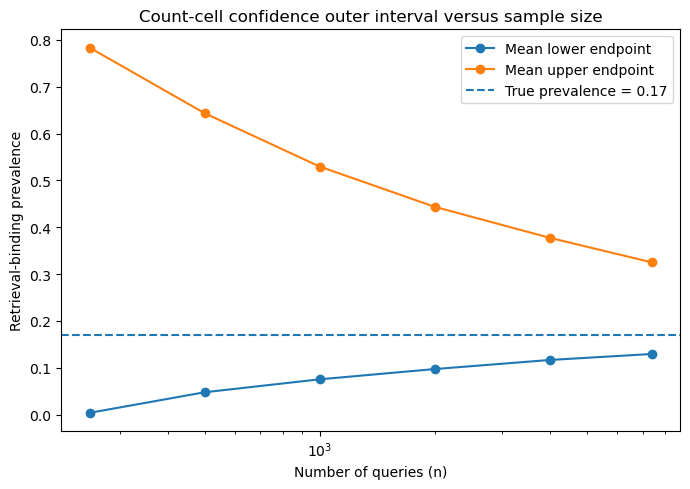

Saved: C:\Users\subir\Documents\RAG_Project\sample_size_design_K5.png


In [50]:
# ============================================================
# CELL 10
# SAMPLE SIZE FIGURE
# ============================================================

plt.figure(
    figsize=(7, 5)
)


plt.plot(
    summary_n["n"],
    summary_n["mean_lower"],
    marker="o",
    label="Mean lower endpoint"
)


plt.plot(
    summary_n["n"],
    summary_n["mean_upper"],
    marker="o",
    label="Mean upper endpoint"
)


plt.axhline(
    true_binding,
    linestyle="--",
    label="True prevalence = 0.17"
)


plt.xscale(
    "log"
)


plt.xlabel(
    "Number of queries (n)"
)

plt.ylabel(
    "Retrieval-binding prevalence"
)

plt.title(
    "Count-cell confidence outer interval versus sample size"
)

plt.legend()

plt.tight_layout()


figure_path = os.path.join(
    project_folder,
    "sample_size_design_K5.png"
)


plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    "Saved:",
    figure_path
)

In [51]:
# ============================================================
# CELL 11
# REFINED POSITIVE-LOWER THRESHOLD
# ============================================================

n_fine = [
    250,
    300,
    350,
    400,
    450,
    500
]

R_fine = 40


rng_fine = np.random.default_rng(
    20261109
)


fine_results = []


for n_test in n_fine:

    print(
        "\nn =",
        n_test
    )


    for r in range(R_fine):

        counts_r = (
            rng_fine.multinomial(
                n_test,
                pi_pop
            )
        )


        pi_r = (
            counts_r
            /
            n_test
        )


        lo_r, up_r = (
            clopper_pearson_box(
                counts_r,
                alpha=alpha
            )
        )


        result_r = (
            system5["certificate"](
                pi_r,
                cell_box=(
                    lo_r,
                    up_r
                )
            )
        )


        fine_results.append(
            {
                "n":
                    n_test,

                "rep":
                    r + 1,

                "lower":
                    result_r["lower"],

                "upper":
                    result_r["upper"],

                "width":
                    result_r["upper"]
                    -
                    result_r["lower"],

                "positive_lower":
                    (
                        result_r["lower"]
                        > 0
                    ),

                "covered":
                    (
                        result_r["lower"]
                        <=
                        true_binding
                        <=
                        result_r["upper"]
                    )
            }
        )


    print(
        "Finished n =",
        n_test
    )


fine_df = pd.DataFrame(
    fine_results
)


fine_summary = (
    fine_df
    .groupby("n")
    .agg(
        positive_lower=(
            "positive_lower",
            "mean"
        ),

        coverage=(
            "covered",
            "mean"
        ),

        mean_lower=(
            "lower",
            "mean"
        ),

        mean_upper=(
            "upper",
            "mean"
        ),

        mean_width=(
            "width",
            "mean"
        ),

        median_width=(
            "width",
            "median"
        )
    )
    .reset_index()
)


display(
    fine_summary
)


fine_df.to_csv(
    os.path.join(
        project_folder,
        "mc_positive_lower_threshold.csv"
    ),
    index=False
)


fine_summary.to_csv(
    os.path.join(
        project_folder,
        "mc_positive_lower_threshold_summary.csv"
    ),
    index=False
)


print(
    "Refined threshold results saved."
)


n = 250
Finished n = 250

n = 300
Finished n = 300

n = 350
Finished n = 350

n = 400
Finished n = 400

n = 450
Finished n = 450

n = 500
Finished n = 500


,n,positive_lower,coverage,mean_lower,mean_upper,mean_width,median_width
0,250,0.150,1.0,0.001787,0.786804,0.785017,0.798208
1,300,0.600,1.0,0.011161,0.731345,0.720184,0.718207
2,350,0.675,1.0,0.016445,0.706003,0.689558,0.686028
3,400,0.800,1.0,0.019732,0.664025,0.644292,0.645120
4,450,0.950,1.0,0.035041,0.650539,0.615498,0.616289
5,500,0.975,1.0,0.050309,0.632867,0.582558,0.583314


Refined threshold results saved.


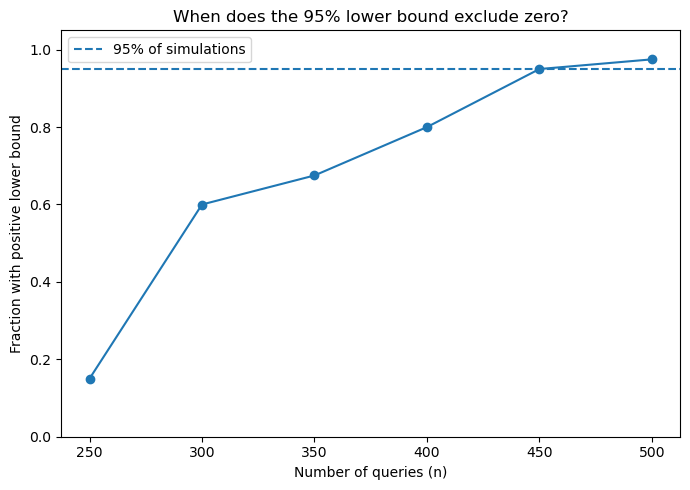

Saved: C:\Users\subir\Documents\RAG_Project\positive_lower_probability_K5.png


In [52]:
# ============================================================
# CELL 12
# POSITIVE LOWER-BOUND FIGURE
# ============================================================

plt.figure(
    figsize=(7, 5)
)


plt.plot(
    fine_summary["n"],
    fine_summary["positive_lower"],
    marker="o"
)


plt.axhline(
    0.95,
    linestyle="--",
    label="95% of simulations"
)


plt.xlabel(
    "Number of queries (n)"
)

plt.ylabel(
    "Fraction with positive lower bound"
)

plt.title(
    "When does the 95% lower bound exclude zero?"
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.tight_layout()


threshold_figure = os.path.join(
    project_folder,
    "positive_lower_probability_K5.png"
)


plt.savefig(
    threshold_figure,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    "Saved:",
    threshold_figure
)

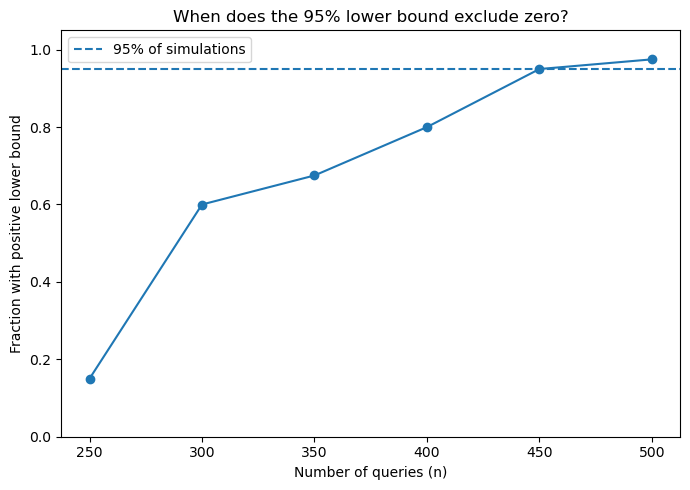

Saved: C:\Users\subir\Documents\RAG_Project\positive_lower_probability_K5.png


In [53]:
# ============================================================
# CELL 12
# POSITIVE LOWER-BOUND FIGURE
# ============================================================

plt.figure(
    figsize=(7, 5)
)


plt.plot(
    fine_summary["n"],
    fine_summary["positive_lower"],
    marker="o"
)


plt.axhline(
    0.95,
    linestyle="--",
    label="95% of simulations"
)


plt.xlabel(
    "Number of queries (n)"
)

plt.ylabel(
    "Fraction with positive lower bound"
)

plt.title(
    "When does the 95% lower bound exclude zero?"
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.tight_layout()


threshold_figure = os.path.join(
    project_folder,
    "positive_lower_probability_K5.png"
)


plt.savefig(
    threshold_figure,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    "Saved:",
    threshold_figure
)

In [54]:
# ============================================================
# CELL 13
# n x K MONTE CARLO STUDY
# ============================================================

K_grid_mc = [
    2,
    3,
    4,
    5
]

n_grid_mc = [
    500,
    1000,
    2000
]

R_K = 20


rng_K = np.random.default_rng(
    20261110
)


nk_results = []


for K_test in K_grid_mc:

    system = systems[
        K_test
    ]

    pi_population = (
        population_by_K[
            K_test
        ]
    )


    print(
        "\n############################"
    )

    print(
        "K =",
        K_test,
        "cells =",
        system["N"]
    )

    print(
        "############################"
    )


    for n_test in n_grid_mc:

        print(
            "n =",
            n_test
        )


        for r in range(R_K):

            counts_r = (
                rng_K.multinomial(
                    n_test,
                    pi_population
                )
            )


            pi_r = (
                counts_r
                /
                n_test
            )


            lo_r, up_r = (
                clopper_pearson_box(
                    counts_r,
                    alpha=alpha
                )
            )


            result_r = (
                system[
                    "certificate"
                ](
                    pi_r,
                    cell_box=(
                        lo_r,
                        up_r
                    )
                )
            )


            nk_results.append(
                {
                    "K":
                        K_test,

                    "n":
                        n_test,

                    "rep":
                        r + 1,

                    "lower":
                        result_r["lower"],

                    "upper":
                        result_r["upper"],

                    "width":
                        result_r["upper"]
                        -
                        result_r["lower"],

                    "covered":
                        (
                            result_r["lower"]
                            <=
                            true_binding
                            <=
                            result_r["upper"]
                        ),

                    "positive_lower":
                        (
                            result_r["lower"]
                            > 0
                        )
                }
            )


        print(
            "Finished K =",
            K_test,
            "n =",
            n_test
        )


nk_df = pd.DataFrame(
    nk_results
)


nk_summary = (
    nk_df
    .groupby(
        [
            "K",
            "n"
        ]
    )
    .agg(
        coverage=(
            "covered",
            "mean"
        ),

        positive_lower=(
            "positive_lower",
            "mean"
        ),

        mean_lower=(
            "lower",
            "mean"
        ),

        mean_upper=(
            "upper",
            "mean"
        ),

        mean_width=(
            "width",
            "mean"
        ),

        median_width=(
            "width",
            "median"
        )
    )
    .reset_index()
)


display(
    nk_summary
)


nk_df.to_csv(
    os.path.join(
        project_folder,
        "mc_n_by_K.csv"
    ),
    index=False
)


nk_summary.to_csv(
    os.path.join(
        project_folder,
        "mc_n_by_K_summary.csv"
    ),
    index=False
)


print(
    "n x K study saved."
)


############################
K = 2 cells = 27
############################
n = 500
Finished K = 2 n = 500
n = 1000
Finished K = 2 n = 1000
n = 2000
Finished K = 2 n = 2000

############################
K = 3 cells = 64
############################
n = 500
Finished K = 3 n = 500
n = 1000
Finished K = 3 n = 1000
n = 2000
Finished K = 3 n = 2000

############################
K = 4 cells = 125
############################
n = 500
Finished K = 4 n = 500
n = 1000
Finished K = 4 n = 1000
n = 2000
Finished K = 4 n = 2000

############################
K = 5 cells = 216
############################
n = 500
Finished K = 5 n = 500
n = 1000
Finished K = 5 n = 1000
n = 2000
Finished K = 5 n = 2000


,K,n,coverage,positive_lower,mean_lower,mean_upper,mean_width,median_width
0,2,500,1.0,0.7,0.017506,0.644829,0.627323,0.633441
1,2,1000,1.0,1.0,0.060921,0.528281,0.467360,0.466301
2,2,2000,1.0,1.0,0.089035,0.402824,0.313790,0.309283
3,3,500,1.0,1.0,0.040939,0.610340,0.569401,0.553164
4,3,1000,1.0,1.0,0.081015,0.504482,0.423467,0.428557
5,3,2000,1.0,1.0,0.101124,0.426990,0.325866,0.322433
6,4,500,1.0,1.0,0.038693,0.629998,0.591305,0.600910
7,4,1000,1.0,1.0,0.078320,0.512204,0.433884,0.433560
8,4,2000,1.0,1.0,0.099021,0.434289,0.335269,0.333897
9,5,500,1.0,1.0,0.040698,0.627070,0.586372,0.584451


n x K study saved.


In [55]:
# ============================================================
# CELL 14
# FINAL COVERAGE STUDY
#
# K = 5
# n = 1000
# 200 Monte Carlo replications
# ============================================================

R_cov = 200

B_cov = 5000

n_cov = 1000


rng_cov = np.random.default_rng(
    20261112
)


coverage_results = []


for r in range(R_cov):

    # --------------------------------------------------------
    # Sample
    # --------------------------------------------------------

    counts_r = (
        rng_cov.multinomial(
            n_cov,
            pi_pop
        )
    )


    pi_r = (
        counts_r
        /
        n_cov
    )


    # --------------------------------------------------------
    # Exact CP
    # --------------------------------------------------------

    lo_cp, up_cp = (
        clopper_pearson_box(
            counts_r,
            alpha=alpha
        )
    )


    cp_r = (
        system5[
            "certificate"
        ](
            pi_r,
            cell_box=(
                lo_cp,
                up_cp
            )
        )
    )


    # --------------------------------------------------------
    # Count-cell max-t
    # --------------------------------------------------------

    maxt_r = (
        multinomial_maxt_box(
            counts_r,
            alpha=alpha,
            B=B_cov,
            seed=(
                20261112 + r
            )
        )
    )


    maxt_cert_r = (
        system5[
            "certificate"
        ](
            pi_r,
            cell_box=(
                maxt_r["lower"],
                maxt_r["upper"]
            )
        )
    )


    # --------------------------------------------------------
    # Save replication
    # --------------------------------------------------------

    coverage_results.append(
        {
            "rep":
                r + 1,

            "cp_lower":
                cp_r["lower"],

            "cp_upper":
                cp_r["upper"],

            "cp_width":
                cp_r["upper"]
                -
                cp_r["lower"],

            "cp_covered":
                (
                    cp_r["lower"]
                    <=
                    true_binding
                    <=
                    cp_r["upper"]
                ),


            "maxt_lower":
                maxt_cert_r["lower"],

            "maxt_upper":
                maxt_cert_r["upper"],

            "maxt_width":
                maxt_cert_r["upper"]
                -
                maxt_cert_r["lower"],

            "maxt_covered":
                (
                    maxt_cert_r["lower"]
                    <=
                    true_binding
                    <=
                    maxt_cert_r["upper"]
                ),

            "critical_value":
                maxt_r[
                    "critical_value"
                ]
        }
    )


    if (
        (r + 1) % 20
        ==
        0
    ):

        print(
            "Finished",
            r + 1,
            "/",
            R_cov
        )


coverage_df = pd.DataFrame(
    coverage_results
)


coverage_summary = pd.DataFrame(
    {
        "method":
            [
                "Exact Bonferroni-CP",
                "Count-cell max-t"
            ],

        "coverage":
            [
                coverage_df[
                    "cp_covered"
                ].mean(),

                coverage_df[
                    "maxt_covered"
                ].mean()
            ],

        "mean_lower":
            [
                coverage_df[
                    "cp_lower"
                ].mean(),

                coverage_df[
                    "maxt_lower"
                ].mean()
            ],

        "mean_upper":
            [
                coverage_df[
                    "cp_upper"
                ].mean(),

                coverage_df[
                    "maxt_upper"
                ].mean()
            ],

        "mean_width":
            [
                coverage_df[
                    "cp_width"
                ].mean(),

                coverage_df[
                    "maxt_width"
                ].mean()
            ],

        "median_width":
            [
                coverage_df[
                    "cp_width"
                ].median(),

                coverage_df[
                    "maxt_width"
                ].median()
            ]
    }
)


display(
    coverage_summary
)


print(
    "\nMean max-t critical value:",
    coverage_df[
        "critical_value"
    ].mean()
)


# ------------------------------------------------------------
# Monte Carlo coverage counts + exact binomial intervals
# ------------------------------------------------------------

for label, column in [
    (
        "Exact CP",
        "cp_covered"
    ),
    (
        "Count-cell max-t",
        "maxt_covered"
    )
]:

    successes = int(
        coverage_df[
            column
        ].sum()
    )

    total = len(
        coverage_df
    )

    rate = (
        successes
        /
        total
    )

    mc_ci = (
        binomial_exact_interval(
            successes,
            total,
            confidence=0.95
        )
    )

    print(
        "\n",
        label
    )

    print(
        "covered:",
        successes,
        "/",
        total
    )

    print(
        "empirical coverage:",
        round(
            rate,
            4
        )
    )

    print(
        "95% Monte Carlo binomial interval:",
        (
            round(
                mc_ci[0],
                4
            ),
            round(
                mc_ci[1],
                4
            )
        )
    )


# ------------------------------------------------------------
# Save final coverage results
# ------------------------------------------------------------

coverage_df.to_csv(
    os.path.join(
        project_folder,
        "mc_countcell_maxt_coverage_200rep.csv"
    ),
    index=False
)


coverage_summary.to_csv(
    os.path.join(
        project_folder,
        "mc_countcell_maxt_coverage_200rep_summary.csv"
    ),
    index=False
)


print(
    "\nFinal coverage study saved."
)

Finished 20 / 200
Finished 40 / 200
Finished 60 / 200
Finished 80 / 200
Finished 100 / 200
Finished 120 / 200
Finished 140 / 200
Finished 160 / 200
Finished 180 / 200
Finished 200 / 200


,method,coverage,mean_lower,mean_upper,mean_width,median_width
0,Exact Bonferroni-CP,1.0,0.075894,0.526305,0.450410,0.450312
1,Count-cell max-t,1.0,0.091633,0.488956,0.397324,0.396544



Mean max-t critical value: 3.6757258407955224

 Exact CP
covered: 200 / 200
empirical coverage: 1.0
95% Monte Carlo binomial interval: (np.float64(0.9817), 1.0)

 Count-cell max-t
covered: 200 / 200
empirical coverage: 1.0
95% Monte Carlo binomial interval: (np.float64(0.9817), 1.0)

Final coverage study saved.


In [56]:
# ============================================================
# CELL 15
# CHECK SAVED PROJECT FILES
# ============================================================

print(
    "Files in:",
    project_folder
)

print()


for filename in sorted(
    os.listdir(
        project_folder
    )
):

    if (
        filename.endswith(".csv")
        or
        filename.endswith(".png")
        or
        filename.endswith(".ipynb")
    ):

        print(
            filename
        )

Files in: C:\Users\subir\Documents\RAG_Project

count_cell_inference_comparison.csv
mc_K5_n1000_25rep.csv
mc_countcell_maxt_coverage.csv
mc_countcell_maxt_coverage_200rep.csv
mc_countcell_maxt_coverage_200rep_summary.csv
mc_countcell_maxt_coverage_summary.csv
mc_n_by_K.csv
mc_n_by_K_summary.csv
mc_positive_lower_threshold.csv
mc_positive_lower_threshold_summary.csv
mc_sample_size_K5.csv
mc_sample_size_K5_summary.csv
population_identification_by_K.csv
positive_lower_probability_K5.png
sample_size_design_K5.png
